In [37]:
# ===== PDF EXPORT: run this cell by itself AFTER "Run all" has finished =====
# Makes a PDF of this notebook with nothing cut off: long code lines and printed text wrap onto the next line,
# and wide tables and figures shrink to fit the page. This cell is left out of the PDF.
# Google Colab: reads the notebook straight from the browser, so it includes every output (no need to save first).
# Jupyter / VS Code: save the notebook first (Ctrl+S / Cmd+S), since it reads the saved file.
RUN_PDF_EXPORT = True                      # set to True, then run only this cell
NOTEBOOK_FILE = "02_phase3_report.ipynb"                    # only used outside Colab
PDF_FILE = "02_phase3_report.pdf"

if not RUN_PDF_EXPORT:
    print('PDF export is off. After "Run all" finishes, set RUN_PDF_EXPORT = True and run only this cell.')
else:
    import json, os, subprocess, sys, tempfile
    import nbformat
    from nbconvert import HTMLExporter

    # 1. Get the notebook with all of its outputs
    try:
        from google.colab import _message, files
        nb_dict = _message.blocking_request("get_ipynb", timeout_sec=120)["ipynb"]
        in_colab = True
    except ImportError:
        with open(NOTEBOOK_FILE, encoding="utf-8") as f:
            nb_dict = json.load(f)
        in_colab = False
    nb = nbformat.reads(json.dumps(nb_dict), as_version=4)   # also normalizes Colab's format
    nb.cells = [c for c in nb.cells if "RUN_PDF_EXPORT" not in "".join(c.source)]   # leave this cell out

    # 2. Notebook -> HTML, plus print styles so nothing runs off the page
    try:
        exporter = HTMLExporter(template_name="lab")
        html, _ = exporter.from_notebook_node(nb)
    except Exception:
        exporter = HTMLExporter(template_name="classic")
        html, _ = exporter.from_notebook_node(nb)
    print_css = """
    <style>
      @page { size: letter; margin: 0.5in; }
      body { margin: 0 !important; padding: 0 !important; font-size: 10.5pt; }
      .jp-Notebook, #notebook-container, .container { width: 100% !important; max-width: 100% !important;
                                                      padding: 0 !important; margin: 0 !important; box-shadow: none !important; }
      pre, code, .highlight pre, .jp-OutputArea-output pre {
          white-space: pre-wrap !important; word-break: normal !important; overflow-wrap: break-word !important;
          font-size: 8pt !important; }
      .jp-InputArea-editor, .jp-OutputArea, .jp-OutputArea-output, .jp-RenderedHTMLCommon, .output_area, .output_subarea {
          overflow: visible !important; max-width: 100% !important; }
      .jp-InputPrompt, .jp-OutputPrompt, .prompt { min-width: 0 !important; flex: 0 0 44px !important; font-size: 7pt !important; }
      table, .dataframe { font-size: 8pt !important; max-width: 100% !important; table-layout: auto !important; }
      th, td { white-space: normal !important; word-break: normal !important; overflow-wrap: normal !important;
               padding: 2px 5px !important; }   /* wrap only between words, so numbers never split */
      tr, img, svg { break-inside: avoid; }
      img { max-width: 100% !important; height: auto !important; }
      h1, h2, h3, h4 { break-after: avoid; }
      p, li { overflow-wrap: break-word; }
    </style>
    """
    html = html.replace("</head>", print_css + "</head>", 1)
    tmp = tempfile.mkdtemp()
    html_path = os.path.join(tmp, "notebook.html")
    with open(html_path, "w", encoding="utf-8") as f:
        f.write(html)

    # 3. HTML -> PDF with a headless browser (Playwright + Chromium; installed the first time, about 1-2 minutes)
    try:
        import playwright  # noqa: F401
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "playwright"], check=True)
    chrome_path = os.environ.get("CHROME_PATH")   # optional: use an existing Chrome instead of downloading one
    if not chrome_path:
        install = [sys.executable, "-m", "playwright", "install"] + (["--with-deps"] if in_colab else []) + ["chromium"]
        subprocess.run(install, check=True, capture_output=True)
    pdf_path = os.path.abspath(PDF_FILE)
    script = f"""
from playwright.sync_api import sync_playwright
with sync_playwright() as p:
    browser = p.chromium.launch(executable_path={chrome_path!r} or None)
    page = browser.new_page()
    page.goto("file://" + {html_path!r}, wait_until="load")
    page.wait_for_timeout(3000)   # let MathJax and fonts finish
    page.pdf(path={pdf_path!r}, prefer_css_page_size=True, print_background=True)
    browser.close()
"""
    subprocess.run([sys.executable, "-c", script], check=True)
    print(f"Saved {pdf_path}")
    if in_colab:
        files.download(pdf_path)

Saved /content/02_phase3_report.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# INFO 2950 Final Project Phase IV

Aiden Hwang, Anthony Ruiz, Youssef Sarhan

GitHub: https://github.com/Aidennnnnnnnnn/2950-final-project

## Introduction

AI is no longer only a computer science field; it now appears in fields including biology, law, and policy, so students who never take a CS class may still need to understand the capabilities and implications of AI in their fields. This pushes the question of whether Cornell students can learn AI topics in only CS-related courses or throughout the rest of the university.

We study this using Cornell's official course roster, examining both technical and non-technical courses. Computing courses show where AI is taught normally, and courses in other departments show whether AI is reaching students outside computer science. Previous research found that course offerings tend to lag behind both research and job demands (Börner et al., 2018), and demand for computing classes has grown sharply since 2006 (Computing Research Association, 2017). We frame this as a diffusion question, following Rogers (2003), which describes how new ideas spread through a system gradually and unevenly.

Research question: How has AI and Machine Learning (AI/ML) content spread across course levels (introductory, upper-level, and graduate) and across academic disciplines in Cornell's course offerings from Fall 2014 to Fall 2026, and does that spread track public interest in AI as measured by Google Trends?

How we break the question down:
- Levels (Analysis 1): do introductory courses catch up to graduate courses over time?
- Disciplines (Analysis 2): we compare computing departments (CS, INFO, STSCI) with all other departments. We do not run a separate analysis for each department. Instead, we hand-check a sample of courses to see whether AI in non-technical departments is actually taught or only discussed.
- Public interest: does the catalog follow Google search interest in AI?

What counts as "AI/ML content": a course counts as AI/ML if its official title or catalog description contains at least one of our technical AI/ML keywords (seen in cleaning Step 4). We apply the same rule to every department so the comparison is fair. Because a non-technical course can talk about AI without actually teaching it, we also hand-labeled a sample of flagged courses as TEACH, DISCUSS, or MENTION (data description).

Courses listed at both levels: some courses are offered under both an undergraduate and a graduate course code. Our main model keeps both copies, since students can enroll in each one separately. We also re-ran it without the graduate copies, and the result did not change (trickle-down odds ratio 1.002 vs. 1.003, Table R1). A class listed under several departments is counted only once in Analysis 1.

Data: every class Cornell listed in a Fall or Spring semester from Fall 2014 to Fall 2026 through the Class Roster API and monthly U.S. Google search interest in three terms: "machine learning," "artificial intelligence," and "neural network."

"Trickle-down": we use this term throughout our project for the pattern Analysis 1 tests: it is the odds that an intro class is AI/ML grow faster each year than the odds for a graduate class, so intro courses are catching up.

Findings:
- Levels (no evidence of trickle-down): AI/ML grew at every level, and graduate courses had the highest share in both Fall 2014 and Fall 2026. With our keyword flag, intro and graduate odds grew at about the same speed. After removing false positives found by hand labeling, intro odds grew faster, but we checked intro courses more thoroughly than graduate ones, so we treat this as exploratory rather than a definitive finding.
- Technical vs. non-technical: AI/ML is indeed spreading beyond computing. Non-computing odds grew about 25% per year vs. 6% in computing, the number of non-computing departments with any AI/ML course went from 5 to 39, and 69% of distinct AI/ML courses are outside computing.
- Taught vs. discussed: in the courses we hand-checked, AI in computing and engineering is mostly taught, while AI in the social sciences is mostly discussed. AI seems to be reaching non-technical fields more as a topic than as a quantitative method.
- Public interest: Google Trends rises along with the catalog, but it doesn't add a lot once steady growth over time is in the model.

## Data Description and Cleaning

Our data cleaning is in a separate notebook, which can be found on our GitHub.

### Data Collection

We used two datasets, both collected outside this notebook and saved as CSV files in our GitHub repository https://github.com/Aidennnnnnnnnn/2950-final-project. This notebook only loads the files, so anyone can load the data in about a minute instead of waiting hours for downloads.

1. Cornell course listings (`cornell_classes.csv`, 113,971 rows before data cleaning)

Source: Cornell's public Class Roster API (Cornell University Office of the University Registrar, n.d.; https://classes.cornell.edu/api/2.0/). It is the same data behind the course roster website students use to pick classes, so it is the official record of what each department offered each semester. We used it instead of scraping web pages because the API returns clean JSONs with stable field names, and it goes back to Fall 2014. Because it is the official record, it is our main source. The raw download includes many columns we don't need, so our cleaning removes them.

How our script `scrape_cornell.py` works:
1. It asks the API which semesters exist (`config/rosters.json`) and keeps all of them. Data spans 50 terms, from Fall 2014 to Winter 2027.
2. For each semester, it asks which subject codes exist that semester (`config/subjects.json`). We do this every semester because subject codes change: for example, PAM courses moved to PUBPOL when the Brooks School of Public Policy opened. The script also saves each semester's lookup lists (academic careers, academic groups, class levels, and subjects) to `cornell_lookups.csv`.
3. It downloads one page of classes per semester-subject pair (`search/classes.json`). The final file contains 5,965 semester-subject pairs across 50 terms (Fall, Spring, Summer, and Winter, from Fall 2014 to Winter 2027). After cleaning, we only keep Fall and Spring, so our analysis ends at Fall 2026.
4. It stays under the API's limit of one request per second, waits and retries when the server is busy, and saves every response in `raw/`, so it can be stopped and restarted without downloading anything twice.
5. It reads the saved pages and writes the three files described under "Nested fields" in the "Problems we found" section below.

Clarifications on script organization: The script created multiple data sets, partly for ease of organization and mainly for the specific instance in the Nested Fields part of the "Problems we found" section below.

Rate limit: The API documentation asks users to make no more than one request per second. Our script waits 1.05 seconds between requests, so the full download took us around 2-3 hours. This is the reason our first draft only used 18 subjects, but after peer evaluation we decided to download the full, unfiltered dataset anyway.

Problems we found:

An unforeseen problem was that the `cornell_meetings.csv` and `all_classes.jsonl` files were too large in file size to push to GitHub, so we zipped them so that the same information can be put into a smaller file and then pushed to GitHub. We wanted to push the uncleaned, original files to show our original data. The latter file isn't particularly needed, but we wanted to display everything shown by the scraper.

A few attempts didn't initially go through to the Cornell system, but the script was coded to wait a few seconds before trying again, and it was able to finish in a few hours. The script saves every response to disk before moving on and skips pages it already has, so a crash or a closed laptop doesn't mean starting over. It also logs every request and its status.

Nested fields: Each class comes back with lists inside it (sections, meeting times, instructors, cross-listings). One class can have many sections, each with its own instructors, so these don't fit in a one-row-per-class table. The script therefore saves three files: `cornell_classes.csv`: one row per class listing, with only the simple top-level fields. This is the file our cleaning notebook uses. `cornell_meetings.csv`: one row per section meeting, including its instructors (stored as JSON text), and `all_classes.jsonl`: every class listed as how the API returned it.

Cross-listed classes appear more than once, once under each department that lists them. We overlooked this at first, until peer evaluation for Phase II pointed it out. We keep every copy in the raw file and handle it in cleaning (Step 9), because whether to count a class once or per department depends on the question we are evaluating.

A catalog system change in 2025: Starting in Fall 2025, the API stopped returning the catalog's publish date (`catalog_dttm` is empty for Fall 2025 onward), because Cornell moved to a new cataloging system. We checked that the fields we actually use (titles, descriptions, numbers, IDs) are still filled in for those semesters, so they stay in our data.

Why we changed to scanning every single subject as opposed to our initial 18 subjects: Our draft picked 18 subjects by hand, which carried an inherent bias towards finding AI in courses where we already expected it. Using all subjects lets AI courses show up in places we wouldn't have guessed (e.g., plant biology, law, hotel administration). It also means our results describe Cornell's whole catalog, as our research question claims, rather than a set of departments we chose. This was a vital piece of feedback we received from the first round of peer evaluations.

2. Google Trends (`google_trends_raw.csv`, 154 months)

Downloaded from Google Trends (Google, n.d.-b) with the `pytrends` Python library (GeneralMills, n.d.): monthly U.S. search interest for "machine learning", "artificial intelligence", and "neural network" from January 2014 to October 2026. All three terms were requested together so they share the same 0–100 scale (Google sets the highest month in the request to 100).

We use this as a rough measure of public interest in AI to see whether course offerings rise when the public gets more engaged.

### Data Description
(following Gebru et al., 2021, "Datasheets for Datasets")

We produce four tables:
- `classes` (Analysis 1): one row per class offered in a Fall or Spring semester from Fall 2014 to Fall 2026, counted once even if cross-listed (75,082 rows).
- `listings` (Analysis 2): the same classes with one row per department listing (94,190 rows).
- `course_history`: one row per course across all semesters (12,876 courses, 359 ever AI).
- `subj_sem`: one row per department per semester (3,942 rows).

Main attributes:
- Time: `roster`, `strm`, `year`, `semester`, `term_index`, `years_since_start`, `academic_year`.
- The course: `subject`, `department`, `catalog_nbr`, `crse_id`, `crse_offer_nbr`, `title`, `description`, `has_description`.
- Level: `course_level`, `is_intro`, `is_upper`, plus the registrar's `acad_career`.
- AI content: `is_ai`, `ai_keyword`, `mentions_ai`, plus `ai_label`, `is_ai_reviewed`, and `is_ai_teach` (added in Phase III).
- Discipline: `discipline`, `college`, `is_computing`, `is_computing_broad`.
- Counting rules: `is_crosslisted`, `has_level_twin`, `is_upper_twin_copy`.
- Public interest: `trends_index`, `trends_lag1`.

Why this dataset was created: We made it for our INFO 2950 project measuring how AI/ML spreads through a university curriculum, seeing whether it starts in graduate courses and later reaches introductory ones, whether it spreads from computing into other fields, and whether that lines up with public interest in AI.

Who created it and who funded it? Everyone in our group. No funding was used.

How did you create this dataset? What tools, procedures, and data sources did you use? Course data from Cornell's public Class Roster API, collected by our script `scrape_cornell.py`. Search interest from Google Trends via `pytrends`. Cleaning and joining in our cleaning notebook with `pandas`, `numpy`, and `duckdb`.

What processes might have influenced what data was observed and recorded and what was not?
- The roster shows courses departments planned. A course can be listed and then cancelled later, so courses that didn't make the cut can still show up in our data, which means we might slightly overcount.
- Descriptions vary in length and detail. Short or generic descriptions ("Selected topics in...") hide potential AI content. Some courses didn't have descriptions at all.
- Departments that rewrite descriptions often (e.g., special-topics courses) have higher chances of adding AI keywords than departments with fixed descriptions.
- Cornell changed its catalog system in 2025, and descriptions became more filled in over time (7.3% missing in Fall 2014, 1.0% in Fall 2026).
- Google Trends scores come from a sample of searches and are relative, not counts.

What preprocessing was done, and how did the data come to be in the form that you are using? Starting from 113,971 raw rows: kept Fall/Spring (bringing it to 107,894 rows); dropped 29 columns that don't describe course timing, identity, level, or content; dropped 1 row missing an identifier; flagged missing descriptions; created AI flags; grouped subjects into disciplines and removed non-departmental subjects (5,656 rows); removed placeholder courses (8,047 rows); assigned levels and time variables; flagged cross-listings and built per-class and per-listing tables; linked renamed departments; flagged undergraduate/graduate twins; built a per-course history with SQL; and merged rescaled, lagged Google Trends scores.

If people are involved, were they aware of the data collection and if so, what purpose did they expect the data to be used for? There's no data about students. The Class Roster is published by Cornell for anyone to see, and instructor names are public on it, but we don't use them in this phase.

Where can your raw source data be found, if applicable? Our GitHub repository (https://github.com/Aidennnnnnnnnn/2950-final-project).

Added in Phase III:
- Hand labels (cleaning Steps 14b and 14c): We manually checked the 19 intro courses and a random sample of 30 other courses our keywords flagged, labeling each one TEACH, DISCUSS, or MENTION using a written rule, and checked 30 unflagged courses with AI-sounding titles for AI courses our keywords missed. Then we added two corrected AI flags (`is_ai_reviewed`, `is_ai_teach`) that we use as robustness checks.
- When we collected the data: We collected the roster and Google Trends data in October 2026, before our Phase II submission. October 2026 was still in progress, so it is marked incomplete in the Trends file and dropped.

How trustworthy is the data?
- Class Roster API: it is Cornell's own record, the same one students use to enroll, so we trust it for which courses existed, their numbers, and their departments. It is weaker for what is actually taught, as a catalog description is a short summary, not a syllabus, so a course can teach AI without saying so, or mention AI without teaching it.
- Google Trends: Google builds Trends from a sample of searches (Google, n.d.-a) and scales every value against the highest month in the request, so the numbers are relative, not counts, and downloading again can give slightly different values. `pytrends` is also not an official Google tool, which is why we only treat Trends as a rough measure of interest.

Credits. Course data comes from Cornell University's Office of the University Registrar (Class Roster). Search data comes from Google Trends.

### What changed after feedback on Phase II

1. Feedback: Check the Spring 2026 Google Trends spike: plot the three terms by month, and re-run the models without Fall 2026. What we did: We plotted each term by month (Appendix A, Figure T1) and reran both models without Fall 2026 (Tables R1 and R2).
2. Feedback: Write a clear rule for courses that teach, discuss, or only mention AI; review the 19 intro courses first, then samples of flagged and unflagged courses. What we did: We made the TEACH / DISCUSS / MENTION rule, labeled all 19 intro courses (all three of us) and a random sample of 30 other flagged courses, checked 30 unflagged courses, and re-ran both models with the corrected flags (cleaning Steps 14b–14c; Tables L1, L2, R1, R2).
3. Feedback: Instructor research matching: try a small sample only after improving the main analysis, and only if there is capacity. What we did: We put our effort into the two preregistered analyses, the hand labels, and the robustness checks first, since those were what the other comments asked us to fix. We left instructor matching out because matching names to publications needs ORCID and other checks for every single person, which is not very reliable.
4. Feedback: Epoch AI model counts would only give about 13 yearly values and measure something different. What we did: We dropped this idea for those same reasons.
5. Feedback: Keep both "twin" courses in the main analysis, then re-run with only the lower-level version. What we did: We did (Table R1).
6. Feedback: Make plot titles readable without other context. What we did: We cleaned the titles and captions up.


### What changed after feedback on Phase III (Introduction)

1. Feedback: Explain why it matters to look at AI in both technical and non-technical classes. What we did: The new opening explains that AI is used in non-technical fields, and that computing courses show where AI is taught while other departments show whether it reaches students outside computing.
2. Feedback: The intro seemed to measure STEM courses, then shifted to non-technical ones; clarify the focus. What we did: We say up front that we study both on purpose, and added "How we break the question down," which states that Analysis 2 compares computing vs. all other departments rather than analyzing each department separately.
3. Feedback: How do we handle courses listed at both graduate and undergraduate levels? What we did: Added a paragraph to the introduction explaining that both copies stay in the main model and that dropping the graduate copies does not change the result (Table R1).
4. Feedback: Is "trickle-down" used in the conclusions? Why is it defined here? What we did: We now say the term is used throughout; it heads the first finding and Conclusion 1.
5. Feedback: Which Google Trends terms? What we did: We name all three in the Data paragraph.
6. Feedback: Preregistration should persuade the reader the results will be interesting whether or not they are significant. What we did: Added a "Why this matters either way" paragraph under each statement, covering what a significant and a non-significant result would each mean. The hypotheses and analyses are unchanged (we only fixed a typo in Analysis 2: "years × is_computing").
7. Feedback: More markdown between graphs and tables explaining why each analysis is done and why it matters, shorter code cells, more sequential storytelling through the EDA. What we did: Added a descriptive "whole picture" section (Table E1, Figure E1, Table E2) before the models, reorganized the analysis big-to-small into six sections, gave every figure and table a "Why" and a "What it shows", split long cells so each produces one output (for example, the old Figure A2 cell is now Figures A2a and A2b), moved the hand-label section before the robustness checks that use it, and moved the Trends spike check to Appendix A.
8. Feedback: Evaluation of significance needs more discussion of why the results matter. What we did: Each test now explains what the p-value or interval means in plain language, why the result matters for students, and its limits. Added Figure S2 for the Analysis 2 permutation test and fixed a mismatch ("p < 0.004" in the text vs. 0.003 in the output).
9. Feedback: The conclusion didn't mention the evaluation of significance or name specific metrics. What we did: Added a summary table linking each answer to its metrics and section, with a confidence level; each conclusion paragraph now cites them.
10. Feedback: Some ideas unclear on first reading, especially in the evaluation of significance and conclusion. What we did: Rewrote both sections with one point per paragraph, defined each test before reporting it, and named sections by the question they answer.

## Preregistration Statements

### Preregistered Analysis 1: Does AI/ML "trickle down" from graduate to introductory courses?

Hypothesis: AI/ML content enters the curriculum through graduate courses first, and the share of introductory courses that cover AI grows faster each year than the graduate share.

Analysis: Using `classes` (one row per class per semester), we run a logistic regression where we input years since Fall 2014, course level as dummy variables `is_intro` and `is_upper`, the interactions of years with each level, and the previous semester's Google Trends score. We then output whether the class is AI-related, with `is_ai` being 1 or 0. We will test whether β(years × is_intro) is greater than 0, meaning whether the odds of an intro class being AI grow faster per year than a grad class's. We expect β(is_intro) to be less than 0, since intros start lower. Since the same course shows up in many semesters, we group the standard errors by `crse_id`. We also re-run it without the grad "twin" copies to make sure they aren't influencing the result.

Why this matters either way: Intro courses are where most students have initial exposure to a subject, whereas graduate courses reach a small group that has already chosen to specialize in a specific field. If β(years × is_intro) > 0, AI is reaching students before they choose a specialty. If it is 0 or negative, intro courses are not catching up, and because graduate courses start higher, the gap in who can take an AI course keeps widening even as both grow.

### Preregistered Analysis 2: Is AI/ML spreading from computing into other disciplines?

Hypothesis: Departments outside computing are adding AI/ML to their own catalogs over time.

Analysis: Using `listings` (one row per department listing per semester), we conduct a logistic regression where we input years since Fall 2014, whether the listing is in a computing department as the `is_computing` dummy (CS, INFO, STSCI), the interaction years × is_computing, and the previous semester's Google Trends score. Output `is_ai`. We will test whether β(years) is greater than 0, measuring whether the odds of a non-computing listing being AI rise each year. Since listings from the same department are related, we group the standard errors by `department`. We will also rerun it using `is_computing_broad`, counting engineering as computing, and without cross-listed courses to make sure they aren't influencing the result.

Why this matters either way: If β(years) > 0, departments outside computing are adding AI to their own catalogs, so a student in policy, biology, or law can find AI inside their own major. If not, AI stays inside CS, INFO, and STSCI, and students elsewhere have to learn it elsewhere. Comparing with computing departments (the interaction) adds whether other fields are catching up or falling further behind.

## Data Analysis

To run this notebook, put these files, output by our separately submitted data cleaning notebook, in the same folder as this notebook: `classes_analysis_ready.csv`, `course_history.csv`, `listings_analysis_ready.csv`, `trends_monthly_clean.csv`, `ai_labels_final.csv`, `fn_labels_final.csv`.

Loading takes about a minute, and running every cell takes another 5-7 minutes.

In [1]:
# Load the tables from our data cleaning notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn
import statsmodels.api as sm

classes = pd.read_csv("classes_analysis_ready.csv", low_memory=False)    # one row per class per semester
listings = pd.read_csv("listings_analysis_ready.csv", low_memory=False)  # one row per department listing
course_history = pd.read_csv("course_history.csv")                       # one row per course
trends_monthly = pd.read_csv("trends_monthly_clean.csv", parse_dates=["date"])

pd.set_option("display.max_colwidth", None)   # show full course titles (no "..." or other undesirable outputs)
pd.set_option("display.max_columns", None)    # show every column
pd.set_option("display.width", 110)           # wide tables split into blocks that fit the page
%config InlineBackend.figure_format = "retina"   # sharper figures in the PDF
np.random.seed(2950)   # the permutation tests and bootstrap give the same numbers every run

# Semester names in time order, for x axes
semester_names = classes.groupby("term_index")["roster"].first()
print(f"classes: {len(classes):,} rows | listings: {len(listings):,} rows | "
      f"{classes['roster'].nunique()} semesters ({semester_names.iloc[0]} to {semester_names.iloc[-1]})")
print("Hand labels merged in the cleaning notebook:", "is_ai_reviewed" in classes.columns)

classes: 75,082 rows | listings: 94,190 rows | 25 semesters (FA14 to FA26)
Hand labels merged in the cleaning notebook: True


We use `statsmodels` for our regressions because it gives a full regression table with standard errors and p-values. Both preregistered analyses group the standard errors (by `crse_id` for Analysis 1 and by `department` for Analysis 2). The second function turns the coefficients into odds ratios.

In [2]:
# cov_type="cluster" groups the standard errors by course or department, as we preregistered.
# The same course / department shows up in many semesters, so its rows are not independent.
def fit_logit(data, inputs, cluster_col, outcome="is_ai"):
    X = sm.add_constant(data[inputs])
    return sm.Logit(data[outcome], X).fit(cov_type="cluster", cov_kwds={"groups": data[cluster_col]}, disp=0)

def odds_table(model):
    """Turn the log-odds coefficients into odds ratios (e^beta) with their p-values and 95% confidence intervals."""
    ci = model.conf_int()
    return pd.DataFrame({"odds ratio": np.exp(model.params), "p-value": model.pvalues,
                         "95% CI low": np.exp(ci[0]), "95% CI high": np.exp(ci[1])}).round(3)

## How this section is organized:
- Section 1 describes the entire catalog.
- Sections 2 and 3 test whether AI/ML grows at the same speed at every course level (Analysis 1) and in every kind of department (Analysis 2).
- Both models rely on a keyword flag, so Section 4 checks (by our hand checks) whether flagged courses really teach AI.
- Section 5 re-runs both models with those corrections and other changes.
- Section 6 sees whether public interest explains any of the growth.

### 1. A broad perspective of how much of the catalog is AI/ML
Before fitting any model, we need the basic facts of how many classes there are, how many are flagged AI/ML, and how that share changed over 12 years. This also shows how rare AI/ML is.

In [3]:
# Count classes and AI/ML classes in each semester (all levels together)
per_sem = classes.groupby("term_index").agg(classes=("is_ai", "size"), ai_classes=("is_ai", "sum"))
per_sem["pct_ai"] = 100 * per_sem["ai_classes"] / per_sem["classes"]
per_sem["semester"] = per_sem.index.map(semester_names)

print("Table E1. Per-semester share of classes flagged AI/ML (%), FA14 to FA26")
display(per_sem["pct_ai"].describe()[["mean", "std", "min", "max"]].round(2).to_frame("% AI/ML").T)
print("First and last semester:")
display(per_sem.iloc[[0, -1]].set_index("semester").round(2))

Table E1. Per-semester share of classes flagged AI/ML (%), FA14 to FA26


,mean,std,min,max
% AI/ML,1.79,0.96,0.64,3.96


First and last semester:


,classes,ai_classes,pct_ai
semester,,,
FA14,2658,17,0.64
FA26,3140,107,3.41


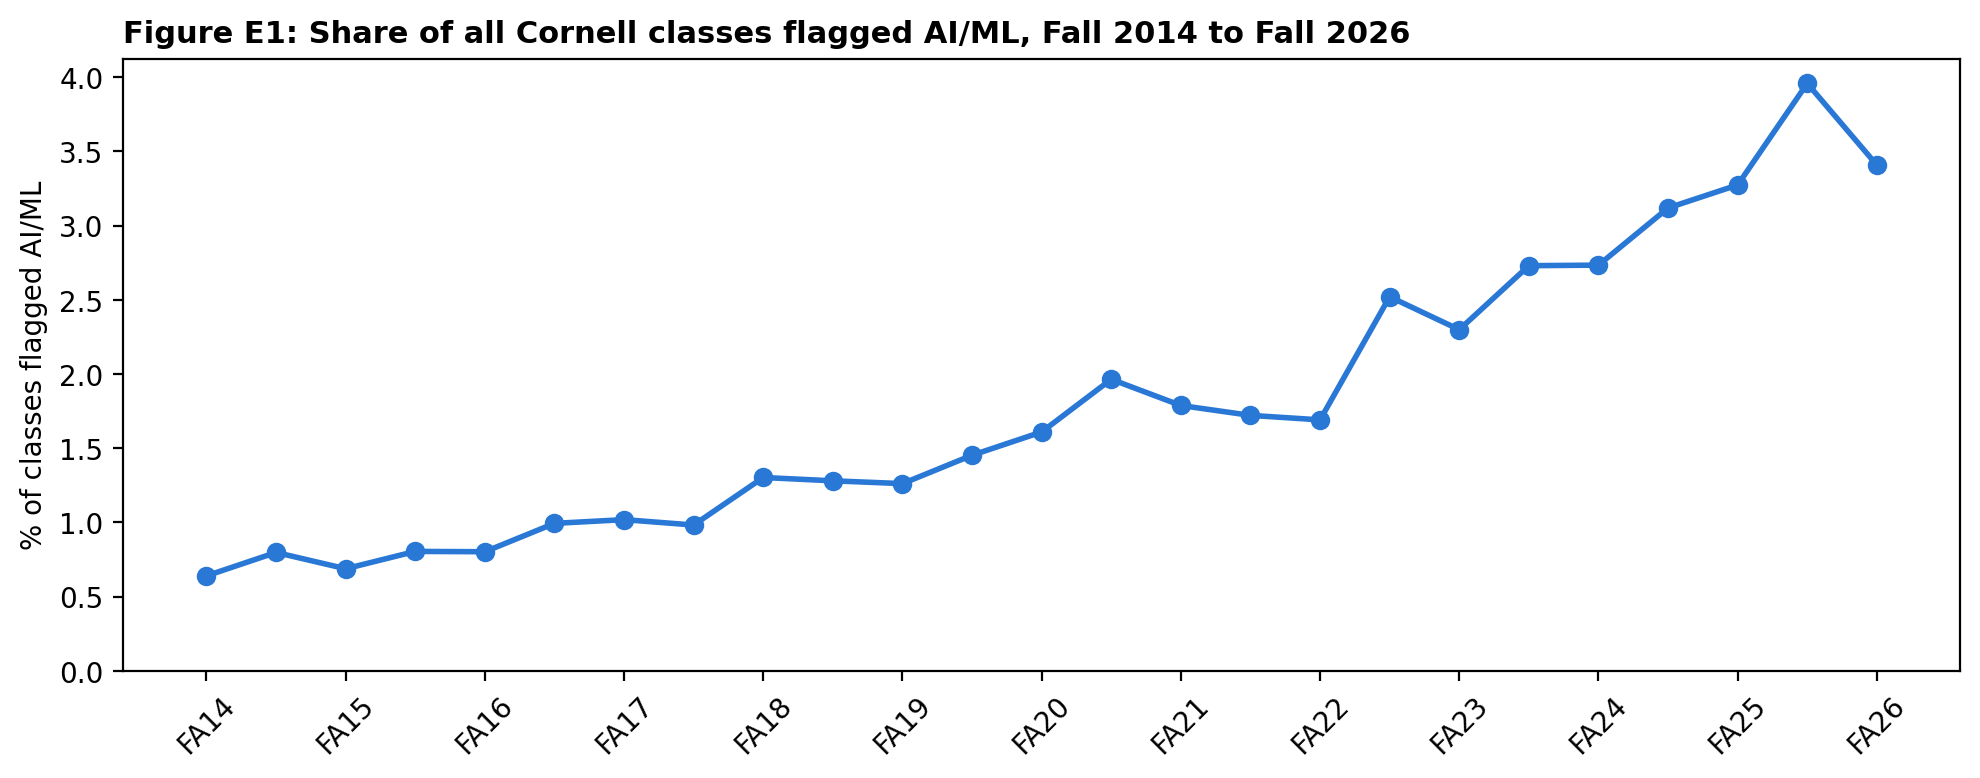

In [4]:
# Figure E1: share of all classes flagged AI/ML in each semester
plt.figure(figsize=(10, 4))
plt.plot(per_sem.index, per_sem["pct_ai"], marker="o", color="#2a78d6", linewidth=2)
plt.xticks(semester_names.index[::2], semester_names.iloc[::2], rotation=45)
plt.ylabel("% of classes flagged AI/ML")
plt.ylim(bottom=0)
plt.title("Figure E1: Share of all Cornell classes flagged AI/ML, Fall 2014 to Fall 2026",
          loc="left", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

What it shows: The share of classes flagged AI/ML rose from 0.64% in Fall 2014 to 3.41% in Fall 2026 (mean 1.79%, standard deviation 0.96 across 25 semesters). AI/ML is growing, but it is still a small slice of the catalog: about 107 of 3140 classes in Fall 2026. It seems to generally be a steady climb.

In [5]:
# Table E2: classes, AI/ML classes, and % AI/ML by level, first vs. last semester
first_last = classes[classes["roster"].isin(["FA14", "FA26"])]
level_table = first_last.groupby(["roster", "course_level"])["is_ai"].agg(["size", "sum", "mean"])
level_table.columns = ["classes", "AI/ML classes", "% AI/ML"]
level_table["% AI/ML"] = 100 * level_table["% AI/ML"]
print("Table E2. AI/ML classes by course level, Fall 2014 vs. Fall 2026")
display(level_table.round(2))

Table E2. AI/ML classes by course level, Fall 2014 vs. Fall 2026


classes  AI/ML classes  % AI/ML
roster course_level                                 
FA14   Grad             1071              9     0.84
       Intro             618              3     0.49
       Upper             969              5     0.52
FA26   Grad             1480             70     4.73
       Intro             679              5     0.74
       Upper             981             32     3.26

What it shows: Graduate courses lead at both ends: 0.84% of graduate classes were AI/ML in Fall 2014 and 4.73% in Fall 2026, compared with 0.49% to 0.74% for intro and 0.52% to 3.26% for upper-level classes. In Fall 2026 that is only 5 intro AI/ML classes. Intro barely moved while the other two levels grew several times over.

### 2. Analysis 1 (preregistered): does AI/ML trickle down from graduate to intro courses?
This tests our first preregistered hypothesis. A logistic regression estimates how fast the odds that a class is AI/ML grow each year, separately for each level, with graduate courses as the comparison group. The key number is the interaction years × is_intro: above 0 means intro odds grow faster than graduate odds (our trickle-down term).

In [6]:
# Preregistered Analysis 1: is_ai ~ years since Fall 2014 + course level (Grad is the comparison group)
# + years x level + last semester's Google Trends score
classes["years_x_intro"] = classes["years_since_start"] * classes["is_intro"]
classes["years_x_upper"] = classes["years_since_start"] * classes["is_upper"]
A1_INPUTS = ["years_since_start", "is_intro", "is_upper", "years_x_intro", "years_x_upper", "trends_lag1"]

a1 = fit_logit(classes, A1_INPUTS, cluster_col="crse_id")   # standard errors grouped by course
print(a1.summary())

                           Logit Regression Results                           
Dep. Variable:                  is_ai   No. Observations:                75082
Model:                          Logit   Df Residuals:                    75075
Method:                           MLE   Df Model:                            6
Date:                Sun, 22 Nov 2026   Pseudo R-squ.:                 0.04975
Time:                        04:38:34   Log-Likelihood:                -6547.5
converged:                       True   LL-Null:                       -6890.4
Covariance Type:              cluster   LLR p-value:                7.642e-145
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -4.6396      0.198    -23.411      0.000      -5.028      -4.251
years_since_start     0.1447      0.019      7.620      0.000       0.108       0.182
is_intro             -1.

In [7]:
# The same model as odds ratios: above 1 = higher odds, below 1 = lower odds
print("Table A1. Analysis 1 as odds ratios")
display(odds_table(a1))

Table A1. Analysis 1 as odds ratios


,odds ratio,p-value,95% CI low,95% CI high
const,0.010,0.000,0.007,0.014
years_since_start,1.156,0.000,1.114,1.200
is_intro,0.169,0.015,0.040,0.713
is_upper,0.596,0.140,0.300,1.185
years_x_intro,1.003,0.967,0.886,1.135
years_x_upper,1.017,0.568,0.961,1.076
trends_lag1,0.999,0.485,0.997,1.002


In [8]:
# Turn the coefficients into a yearly % change in odds for each level, then run the two preregistered tests
b = a1.params
growth_a1 = pd.Series({
    "Grad": np.exp(b["years_since_start"]) - 1,
    "Upper": np.exp(b["years_since_start"] + b["years_x_upper"]) - 1,
    "Intro": np.exp(b["years_since_start"] + b["years_x_intro"]) - 1}) * 100
print("Yearly % change in the odds that a class is AI/ML:")
print(growth_a1.round(1).to_string())

intro_ai = classes[(classes["course_level"] == "Intro") & (classes["is_ai"] == 1)]
print(f"\nIntro AI/ML classes: {intro_ai['crse_id'].nunique()} distinct courses, {len(intro_ai)} class-semesters")
print(f"Preregistered test 1: beta(years x is_intro) > 0?  beta = {b['years_x_intro']:.3f}, "
      f"odds ratio = {np.exp(b['years_x_intro']):.3f}, p = {a1.pvalues['years_x_intro']:.3f}")
print(f"Preregistered expectation: beta(is_intro) < 0?  beta = {b['is_intro']:.3f}, "
      f"odds ratio = {np.exp(b['is_intro']):.3f}, p = {a1.pvalues['is_intro']:.3f}")

Yearly % change in the odds that a class is AI/ML:
Grad     15.6
Upper    17.5
Intro    15.9

Intro AI/ML classes: 19 distinct courses, 72 class-semesters
Preregistered test 1: beta(years x is_intro) > 0?  beta = 0.003, odds ratio = 1.003, p = 0.967
Preregistered expectation: beta(is_intro) < 0?  beta = -1.776, odds ratio = 0.169, p = 0.015


What it shows:
- Same growth at every level. Each year, the odds that a graduate class is AI/ML grow by 15.6% (95% CI 11.4% to 20.0%). Intro odds grow 15.9% a year and upper-level odds 17.5%.
- No trickle-down. The interaction odds ratio is 1.003 (95% CI 0.886 to 1.135, p = 0.967). That is essentially 1: intro and graduate odds grow at the same speed, so our hypothesis is not supported.
- Intro starts far lower, as we expected: odds ratio 0.169 (p = 0.015). At the start of our data, an intro class had about 1/6 the odds of a graduate class of being AI/ML.
- Google Trends adds nothing once time is in the model (odds ratio 0.999 per point, p = 0.485). Section 6 examines this in more detail.

Why it matters: Equal growth rates from unequal starting points mean the absolute gap widens. The same ~16% yearly growth adds far more AI/ML classes at the graduate level than at the intro level.

#### Figure A1: does the Analysis 1 model match the data?
We compare the model's predicted share of AI/ML classes (noted with lines) with the actual share (noted with dots) for each level and semester, and we then look at its Fall 2026 prediction and its largest misses.

In [9]:
# Add the model's predicted probability to every class, then average by semester and level
classes["predicted_a1"] = a1.predict(sm.add_constant(classes[A1_INPUTS]))
by_level = classes.groupby(["term_index", "course_level"])[["is_ai", "predicted_a1"]].mean().reset_index()
by_level[["is_ai", "predicted_a1"]] = by_level[["is_ai", "predicted_a1"]] * 100   # as percents
by_level["semester"] = by_level["term_index"].map(semester_names)
by_level["miss (pct. points)"] = by_level["is_ai"] - by_level["predicted_a1"]

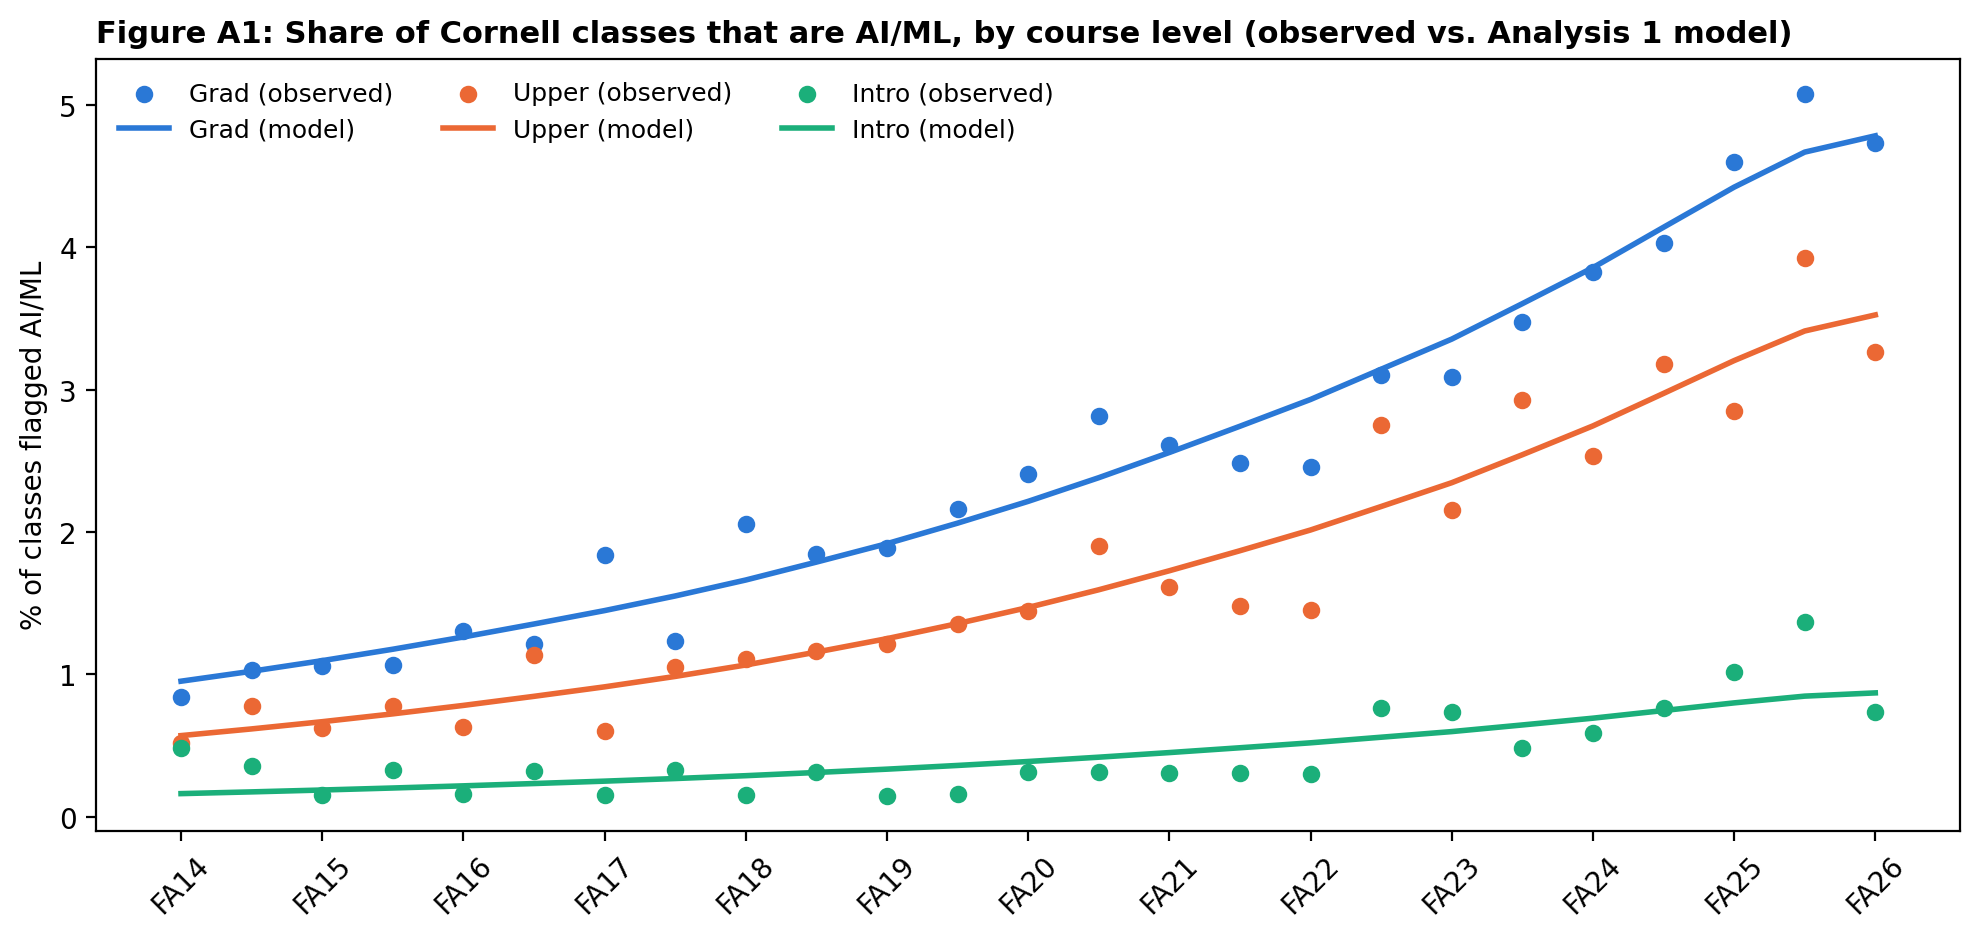

In [10]:
# Figure A1: dots = observed share of AI/ML classes; lines = the model's predictions
colors = {"Grad": "#2a78d6", "Upper": "#eb6834", "Intro": "#1baf7a"}
plt.figure(figsize=(10, 4.8))
for level, color in colors.items():
    d = by_level[by_level["course_level"] == level]
    plt.scatter(d["term_index"], d["is_ai"], color=color, s=28, label=f"{level} (observed)")
    plt.plot(d["term_index"], d["predicted_a1"], color=color, linewidth=2, label=f"{level} (model)")
plt.xticks(semester_names.index[::2], semester_names.iloc[::2], rotation=45)
plt.ylabel("% of classes flagged AI/ML")
plt.title("Figure A1: Share of Cornell classes that are AI/ML, by course level (observed vs. Analysis 1 model)",
          loc="left", fontsize=11, fontweight="bold")
plt.legend(frameon=False, ncol=3, fontsize=9)
plt.tight_layout()
plt.show()

In [11]:
# Predict: Fall 2026 observed vs. predicted. Oddities: where the model misses by the most.
low_years = by_level[(by_level["course_level"] == "Intro") & by_level["term_index"].between(2, 15)]
print("Lowest and highest intro share from FA15 to SP22 (%):", low_years["is_ai"].agg(["min", "max"]).round(2).tolist())
print("\nFall 2026, observed vs. predicted % AI/ML:")
display(by_level[by_level["semester"] == "FA26"][["course_level", "is_ai", "predicted_a1"]].round(2))
print("Largest misses:")
display(by_level.sort_values("miss (pct. points)", key=abs, ascending=False).head(5)
        [["semester", "course_level", "is_ai", "predicted_a1", "miss (pct. points)"]].round(2))

Lowest and highest intro share from FA15 to SP22 (%): [0.15, 0.33]

Fall 2026, observed vs. predicted % AI/ML:


,course_level,is_ai,predicted_a1
72,Grad,4.73,4.78
73,Intro,0.74,0.87
74,Upper,3.26,3.52


Largest misses:


,semester,course_level,is_ai,predicted_a1,miss (pct. points)
53,SP23,Upper,2.75,2.18,0.57
50,FA22,Upper,1.45,2.01,-0.56
70,SP26,Intro,1.37,0.85,0.52
71,SP26,Upper,3.92,3.41,0.51
48,FA22,Grad,2.46,2.93,-0.48


What it shows:
- Predict: For Fall 2026 the model predicts that 4.78% of graduate classes and 0.87% of intro classes are AI/ML; the actual shares are 4.73% and 0.74%. The fit is close for graduate and upper-level courses.
- Oddities: Intro is the weak area. The intro share sits nearly flat at 0.15–0.33% from Fall 2015 to Spring 2022, then rises, jumping to 1.37% in Spring 2026 (0.85% predicted) before falling back in Fall 2026. One steady growth rate can't capture going down and then up. The other large misses (upper-level, Fall 2022 and Spring 2023) are about half a percentage point.

### 3. Analysis 2 (preregistered): is AI/ML spreading from computing into other disciplines?
This tests our second preregistered hypothesis, which is where the technical vs. non-technical comparison from our introduction is. We use one row per department listing, so cross-listed courses count for each department that lists it. β(years): above 0 means a non-computing listing becomes more likely to be AI/ML each year. The interaction years × is_computing (not preregistered) tells us whether computing grows faster or slower than everyone else.

In [12]:
# Preregistered Analysis 2
listings["years_x_computing"] = listings["years_since_start"] * listings["is_computing"]
A2_INPUTS = ["years_since_start", "is_computing", "years_x_computing", "trends_lag1"]

a2 = fit_logit(listings, A2_INPUTS, cluster_col="department")   # standard errors grouped by department
print(a2.summary())

                           Logit Regression Results                           
Dep. Variable:                  is_ai   No. Observations:                94190
Model:                          Logit   Df Residuals:                    94185
Method:                           MLE   Df Model:                            4
Date:                Sun, 22 Nov 2026   Pseudo R-squ.:                  0.1802
Time:                        04:38:37   Log-Likelihood:                -6880.6
converged:                       True   LL-Null:                       -8393.4
Covariance Type:              cluster   LLR p-value:                     0.000
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -6.2065      0.287    -21.619      0.000      -6.769      -5.644
years_since_start     0.2213      0.022      9.856      0.000       0.177       0.265
is_computing          4.

In [13]:
# The same model in terms of odds ratios
print("Table A2. Analysis 2 as odds ratios")
display(odds_table(a2))

Table A2. Analysis 2 as odds ratios


,odds ratio,p-value,95% CI low,95% CI high
const,0.002,0.000,0.001,0.004
years_since_start,1.248,0.000,1.194,1.304
is_computing,72.718,0.000,32.615,162.131
years_x_computing,0.850,0.000,0.813,0.887
trends_lag1,1.000,0.787,0.997,1.002


In [14]:
# Yearly percent change in odds for each group, including the preregistered test
b2 = a2.params
growth_a2 = pd.Series({
    "Non-computing departments": np.exp(b2["years_since_start"]) - 1,
    "Computing (CS, INFO, STSCI)": np.exp(b2["years_since_start"] + b2["years_x_computing"]) - 1}) * 100
print("Yearly % change in the odds that a listing is AI/ML:")
print(growth_a2.round(1).to_string())
print(f"\nPreregistered test 2: beta(years) > 0 for non-computing listings?  beta = {b2['years_since_start']:.3f}, "
      f"p = {a2.pvalues['years_since_start']:.2g}")
print(f"Not preregistered (exploratory): beta(years x is_computing) = {b2['years_x_computing']:.3f}, "
      f"odds ratio = {np.exp(b2['years_x_computing']):.3f}, p = {a2.pvalues['years_x_computing']:.2g}")

Yearly % change in the odds that a listing is AI/ML:
Non-computing departments      24.8
Computing (CS, INFO, STSCI)     6.0

Preregistered test 2: beta(years) > 0 for non-computing listings?  beta = 0.221, p = 6.4e-23
Not preregistered (exploratory): beta(years x is_computing) = -0.163, odds ratio = 0.850, p = 2.4e-13


What it shows:
- Our hypothesis is supported. Each year, the odds that a non-computing listing is AI/ML are multiplied by 1.248, a 24.8% yearly increase (p = 6.4 × 10⁻²³).
- Other fields grow about four times faster than computing (6.0% a year), but from a lower beginning: at the beginning of our data, a computing listing had about 73 times the odds of being AI/ML (odds ratio 72.7).

This is significant because it is direct evidence that AI is reaching students outside CS, INFO, and STSCI, in addition to growing in subjects it already was in.


#### Figure A2a: does the Analysis 2 model match the data?
As with Analysis 1, we compare predicted and actual shares of AI/ML listings. We use a log scale because computing's share is about 9 to 80 times larger than everyone else's depending on the semester, so both groups wouldn't be readable on an ordinary axis.

In [15]:
# Predicted probability for every listing, averaged by semester and group
listings["predicted_a2"] = a2.predict(sm.add_constant(listings[A2_INPUTS]))
by_group = listings.groupby(["term_index", "is_computing"])[["is_ai", "predicted_a2"]].mean().reset_index()
by_group[["is_ai", "predicted_a2"]] = by_group[["is_ai", "predicted_a2"]] * 100   # as percents
by_group["group"] = by_group["is_computing"].map({1: "Computing", 0: "Non-computing"})
by_group["semester"] = by_group["term_index"].map(semester_names)
by_group["miss (pct. points)"] = by_group["is_ai"] - by_group["predicted_a2"]

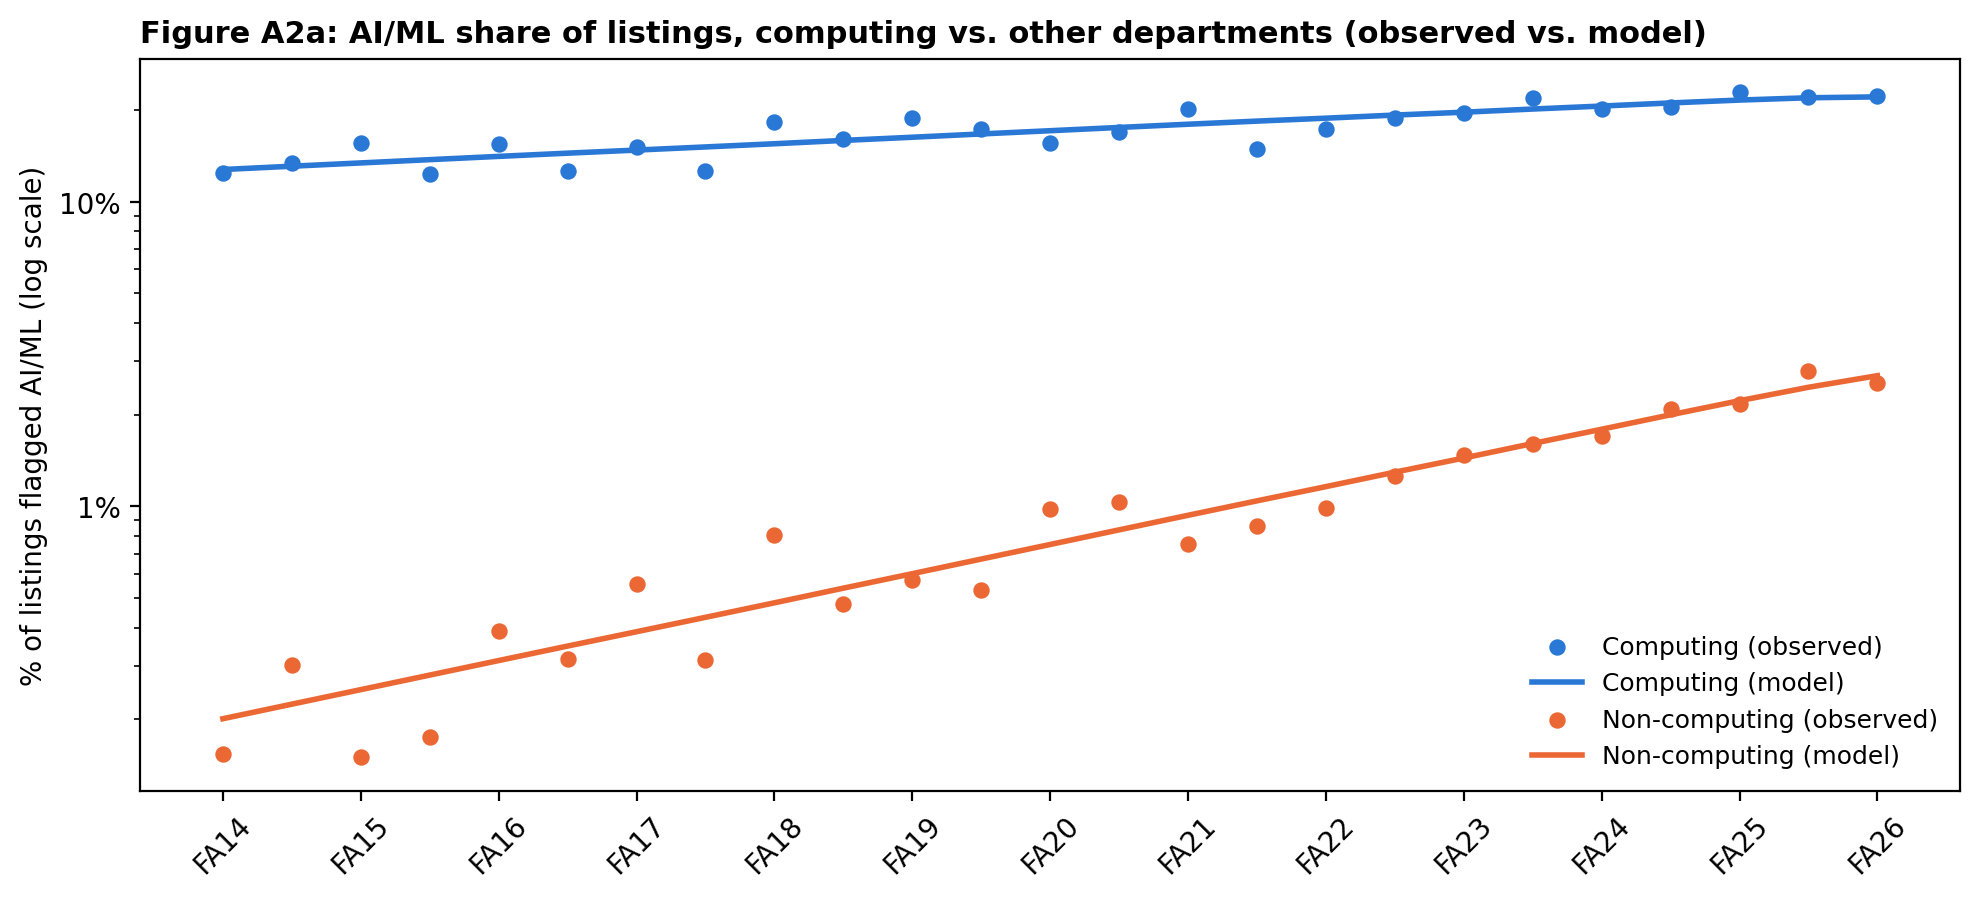

In [16]:
# Figure A2a: observed (in dots) vs. predicted (in lines) share of AI/ML listings, log scale
plt.figure(figsize=(10, 4.6))
for comp, color, name in [(1, "#2a78d6", "Computing"), (0, "#eb6834", "Non-computing")]:
    d = by_group[by_group["is_computing"] == comp]
    plt.scatter(d["term_index"], d["is_ai"], color=color, s=24, label=f"{name} (observed)")
    plt.plot(d["term_index"], d["predicted_a2"], color=color, linewidth=2, label=f"{name} (model)")
plt.yscale("log")
plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}%"))   # 1%, 10% instead of 10^0, 10^1
plt.xticks(semester_names.index[::2], semester_names.iloc[::2], rotation=45)
plt.ylabel("% of listings flagged AI/ML (log scale)")
plt.title("Figure A2a: AI/ML share of listings, computing vs. other departments (observed vs. model)",
          loc="left", fontsize=11, fontweight="bold")
plt.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

In [17]:
# Observed shares at the start and end, the Fall 2026 prediction, and the largest misses
print("Observed % AI/ML listings, FA14 vs. FA26:")
display(by_group.pivot(index="semester", columns="group", values="is_ai").loc[["FA14", "FA26"]].round(2))
print("Fall 2026, observed vs. predicted % AI/ML listings:")
display(by_group[by_group["semester"] == "FA26"][["group", "is_ai", "predicted_a2"]].round(2))
print("Largest misses:")
display(by_group.sort_values("miss (pct. points)", key=abs, ascending=False).head(5)
        [["semester", "group", "is_ai", "predicted_a2", "miss (pct. points)"]].round(2))

Observed % AI/ML listings, FA14 vs. FA26:


group,Computing,Non-computing
semester,,
FA14,12.40,0.15
FA26,22.16,2.54


Fall 2026, observed vs. predicted % AI/ML listings:


,group,is_ai,predicted_a2
48,Non-computing,2.54,2.69
49,Computing,22.16,22.10


Largest misses:


,semester,group,is_ai,predicted_a2,miss (pct. points)
31,SP22,Computing,14.95,18.40,-3.45
17,FA18,Computing,18.24,15.51,2.74
15,SP18,Computing,12.58,15.14,-2.56
21,FA19,Computing,18.79,16.29,2.50
29,FA21,Computing,20.22,17.97,2.24


What it shows:
- Shares: From Fall 2014 to Fall 2026, non-computing grew from 0.15% to 2.54% of listings (around  17 times larger) and computing grew from 12.4% to 22.2%.
- Predict: The model expects 2.69% (non-computing) and 22.10% (computing) in Fall 2026; actual: 2.54% and 22.16%.
- Oddities: Five of the largest misses were in computing, which jumps up to 3.5 percentage points around the curve (Spring 2022: 15.0% vs. 18.4% predicted).

#### Figure A2b (not preregistered): how many non-computing departments offer any AI/ML course?
Counting departments shows the breadth of AI distribution, which a single share can still hide.

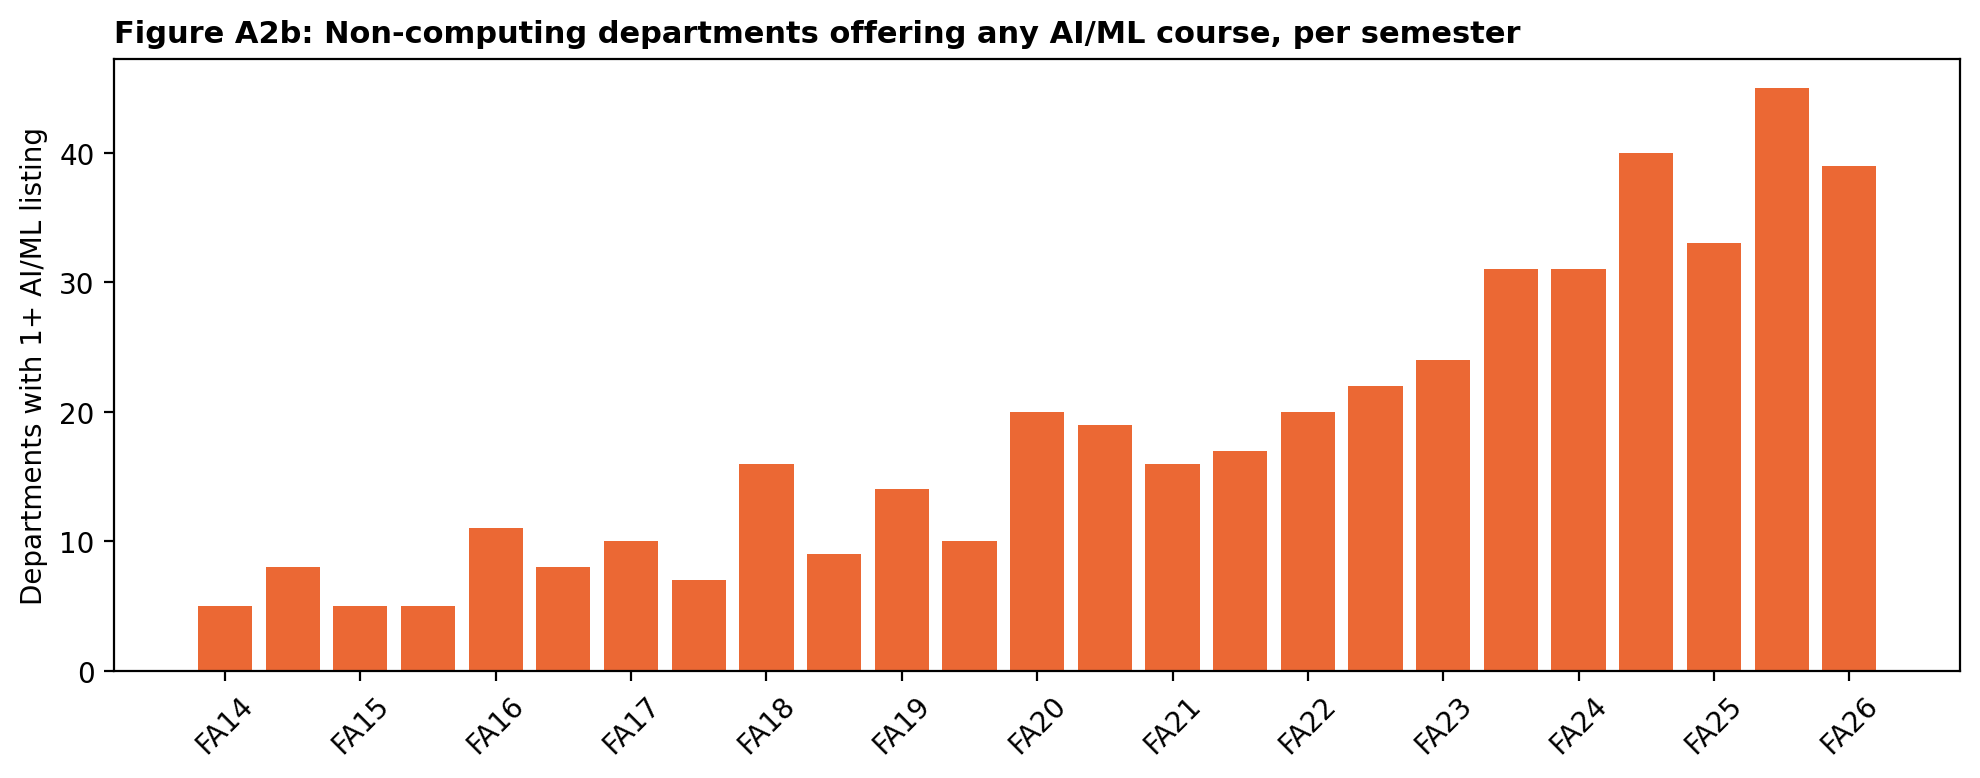

In [18]:
# For each semester, count the non-computing departments with at least one AI/ML listing
non_computing = listings[listings["is_computing"] == 0]
departments_with_ai = non_computing.groupby(["term_index", "department"])["is_ai"].max().groupby("term_index").sum()

plt.figure(figsize=(10, 4))
plt.bar(departments_with_ai.index, departments_with_ai.values, color="#eb6834")
plt.xticks(semester_names.index[::2], semester_names.iloc[::2], rotation=45)
plt.ylabel("Departments with 1+ AI/ML listing")
plt.title("Figure A2b: Non-computing departments offering any AI/ML course, per semester",
          loc="left", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

In [19]:
# Breadth in numbers: departments at the start and end, and distinct AI/ML courses outside Computing
print(f"Non-computing departments with any AI/ML listing: {departments_with_ai.iloc[0]} in FA14 -> "
      f"{departments_with_ai.iloc[-1]} in FA26 (most: {departments_with_ai.max()})")
ai_course_list = course_history[course_history["ever_ai"] == 1]
outside = (ai_course_list["discipline"] != "Computing").sum()
print(f"Distinct AI/ML courses whose latest listing is outside Computing: {outside} of {len(ai_course_list)} "
      f"({outside / len(ai_course_list):.0%})")

Non-computing departments with any AI/ML listing: 5 in FA14 -> 39 in FA26 (most: 45)
Distinct AI/ML courses whose latest listing is outside Computing: 248 of 359 (69%)


What it shows: AI/ML is spreading across many departments. Five non-computing departments offered an AI/ML course in Fall 2014 and 39 in Fall 2026, and 248 of the 359 distinct AI/ML courses (69%) sit outside the Computing group.

### 4. Checking our keyword flag by hand to see if it's actually AI
We hand-labeled all 19 intro courses flagged, a random sample of 30 of the other 340 flagged courses, and 30 unflagged courses with AI-sounding titles. Each got one label: TEACH (when AI is a method taught in the course), DISCUSS (when AI is a topic of discussion), or MENTION (when AI appears only in passing). A flag counts as correct if the course is TEACH or DISCUSS. The 30 random courses give us a rough estimate for all upper-level and graduate flags.

In [20]:
# Load the final hand labels and drop courses the labelers could not resolve
labels = pd.read_csv("ai_labels_final.csv").merge(
    course_history[["crse_id", "subject", "catalog_nbr", "title", "discipline", "first_ai_level"]], on="crse_id")
labels = labels[labels["final_label"] != "UNRESOLVED"]

kept = labels["final_label"].isin(["TEACH", "DISCUSS"]).mean()
double = labels[labels["n_labelers"] > 1]
print(f"Flags kept (TEACH or DISCUSS): {kept:.0%} of {len(labels)} courses. "
      f"Labelers agreed on {double['agreed'].mean():.0%} of the {len(double)} courses labeled by 2+ people.")
print("\nTable L1. Share of courses with each label, by the level of their first AI semester")
display(pd.crosstab(labels["first_ai_level"], labels["final_label"], normalize="index").round(2))

Flags kept (TEACH or DISCUSS): 80% of 49 courses. Labelers agreed on 32% of the 19 courses labeled by 2+ people.

Table L1. Share of courses with each label, by the level of their first AI semester


final_label,DISCUSS,MENTION,TEACH
first_ai_level,,,
Grad,0.26,0.09,0.65
Intro,0.42,0.32,0.26
Upper,0.29,0.29,0.43


What it shows: 80% of the 49 labeled courses are still aligned with AI (39 of 49 in total). Intro flags are the weakest: 32% of intro courses only mention AI compared with 9% of graduate courses, and only 26% of intro courses teach AI as compared with 65% of graduate courses.

In [21]:
# Finding which intro courses are false positives and how many class-semesters they account for
intro_flagged = classes[(classes["course_level"] == "Intro") & (classes["is_ai"] == 1)]
mention = intro_flagged[intro_flagged["ai_label"] == "MENTION"]
print(f"Intro AI class-semesters (keyword flag): {len(intro_flagged)}, labeled MENTION: {len(mention)}")
print(mention.groupby(["subject", "catalog_nbr", "title"]).size().sort_values(ascending=False).to_string())

Intro AI class-semesters (keyword flag): 72, labeled MENTION: 44
subject  catalog_nbr  title                                                                
INFO     2950         Introduction to Data Science                                             16
ECON     2040         Networks                                                                 12
PLBIO    2490         Hollywood Biology: Science in Cinema                                      6
ILRHR    2685         Building Better Jobs: Organizational Levers for Improving Job Quality     4
PLSCI    2490         Hollywood Biology: Science in Cinema                                      2
BIOPL    2490         Hollywood Biology: Science in Cinema                                      1
ECON     2850         Networks                                                                  1
INFO     2300         Server-Side Web Development                                               1
         2310         Interactive Web Development          

In [22]:
# Intro AI class-semesters per academic year: keyword flag vs. the two hand-checked flags
display(classes[classes["course_level"] == "Intro"]
        .groupby("academic_year")[["is_ai", "is_ai_reviewed", "is_ai_teach"]].sum().T)

academic_year,2014–15,2015–16,2016–17,2017–18,2018–19,2019–20,2020–21,2021–22,2022–23,2023–24,2024–25,2025–26,2026–27
is_ai,5,3,3,3,3,2,4,4,7,8,9,16,5
is_ai_reviewed,2,0,0,0,0,0,1,1,2,4,6,10,2
is_ai_teach,0,0,0,0,0,0,1,1,1,3,6,7,1


What it shows: 44 of the 72 intro AI/ML class-semesters are MENTION false positives, mostly Introduction to Data Science (INFO 2950, 16) and Networks (ECON 2040, 12). With the hand-checked flag, intro AI/ML stays at 0–2 class-semesters a year through 2022–23, then climbs to 10 in 2025–26. So the flat early intro years in Figure A1 were mostly noise, and the late rise is closer to real.

In [23]:
# Label mix by discipline, plus unflagged courses that turned out to be AI/ML (false negatives)
print("Table L2. Share of courses with each label, by discipline")
display(pd.crosstab(labels["discipline"], labels["final_label"], normalize="index").round(2))

fn = pd.read_csv("fn_labels_final.csv")
missed = fn[fn["label"].isin(["TEACH", "DISCUSS"])]
print(f"\nUnflagged AI-adjacent courses checked: {len(fn)}; actually AI/ML: {len(missed)}")
display(missed[["subject", "catalog_nbr", "title", "label"]])

Table L2. Share of courses with each label, by discipline


final_label,DISCUSS,MENTION,TEACH
discipline,,,
Computing,0.13,0.27,0.60
Engineering & Math,0.09,0.09,0.82
Humanities & Arts,0.50,0.00,0.50
Natural & Life Sciences,0.50,0.25,0.25
"Social Sciences, Business & Law",0.59,0.24,0.18



Unflagged AI-adjacent courses checked: 30; actually AI/ML: 2


,subject,catalog_nbr,title,label
17,INFO,5610,"Sensors, Systems and Algorithms for Precision Behavioral Health",DISCUSS
27,CS,7890,Seminar in Theory of Algorithms and Computing,DISCUSS


What it shows:
- Technical vs. non-technical: In computing and engineering, flagged AI is mostly taught (60% and 82% TEACH). In the social sciences, business, and law it is mostly discussed (59% DISCUSS, 18% TEACH).
- Missed courses are rare: Only 2 of 30 unflagged AI-sounding courses turned out to be AI/ML.
- The labels are partly subjective: All three of us agreed on 32% of the intro courses (at least two agreed on every one), and every disagreement involved DISCUSS. We used one written rule to keep this consistent.

### 5. To see if the results are stable, we run robustness checks.
Each row re-runs one preregistered model with one change to see whether a conclusion depends on that choice. Preregistered checks: without the graduate twin copies (Analysis 1); engineering counted as computing, and without cross-listed courses (Analysis 2). Reviewer-requested checks: without Fall 2026 (the only semester affected by the Google Trends spike, Section 6), and the hand-checked flags from Section 4. We also drop Google Trends once to see whether it changes the time results.

In [24]:
# Re-fit a preregistered model with one change and keep only the key numbers
def a1_check(name, data, outcome="is_ai", inputs=A1_INPUTS):
    m = fit_logit(data, inputs, "crse_id", outcome)
    p = m.params
    return {"check": name, "rows": int(m.nobs),
            "odds ratio years x intro": np.exp(p["years_x_intro"]), "p-value": m.pvalues["years_x_intro"],
            "Grad % per year": 100 * (np.exp(p["years_since_start"]) - 1),
            "Intro % per year": 100 * (np.exp(p["years_since_start"] + p["years_x_intro"]) - 1)}

def a2_check(name, data, outcome="is_ai", computing="is_computing", inputs=None):
    d = data.copy()
    d["comp"] = d[computing]
    d["years_x_comp"] = d["years_since_start"] * d["comp"]
    m = fit_logit(d, inputs or ["years_since_start", "comp", "years_x_comp", "trends_lag1"], "department", outcome)
    p = m.params
    return {"check": name, "rows": int(m.nobs),
            "Non-computing % per year": 100 * (np.exp(p["years_since_start"]) - 1),
            "p-value (years)": m.pvalues["years_since_start"],
            "odds ratio years x computing": np.exp(p["years_x_comp"]),
            "p-value (interaction)": m.pvalues["years_x_comp"]}

In [25]:
# Table R1: Analysis 1 under each change
no_trends_a1 = [x for x in A1_INPUTS if x != "trends_lag1"]
a1_rows = [a1_check("Preregistered model", classes),
           a1_check("Without Fall 2026 (reviewer Q1)", classes[classes["roster"] != "FA26"]),
           a1_check("Without the grad twin copies (preregistered check, reviewer Q5)",
                    classes[classes["is_upper_twin_copy"] == 0]),
           a1_check("Without Google Trends", classes, inputs=no_trends_a1),
           a1_check("Hand-checked flag (TEACH + DISCUSS)", classes, outcome="is_ai_reviewed"),
           a1_check("Hand-checked flag (TEACH only)", classes, outcome="is_ai_teach")]
print("Table R1. Analysis 1 checks")
display(pd.DataFrame(a1_rows).set_index("check").round(3))

Table R1. Analysis 1 checks


,rows,odds ratio years x intro,p-value,Grad % per year,Intro % per year
check,,,,,
Preregistered model,75082,1.003,0.967,15.574,15.876
Without Fall 2026 (reviewer Q1),71942,1.008,0.904,13.728,14.680
"Without the grad twin copies (preregistered check, reviewer Q5)",67600,1.002,0.974,15.311,15.552
Without Google Trends,75082,1.003,0.967,15.122,15.421
Hand-checked flag (TEACH + DISCUSS),75082,1.230,0.039,15.867,42.514
Hand-checked flag (TEACH only),75082,1.415,0.000,15.746,63.777


What it shows (Analysis 1): With the keyword flag, the trickle-down odds ratio changes a very small amount (1.002 to 1.008, all p > 0.9) when we drop Fall 2026, the twin copies, or Google Trends. With the hand-checked flags, odds ratio becomes 1.230 (p = 0.039) for TEACH + DISCUSS and 1.415 (p < 0.001) for TEACH only, with intro odds growing 42.5% and 63.8% a year. That happens because removing the 44 intro false positives (which we described in Section 4) deletes the early intro years. We checked every intro course but only 30 of 340 others, so most graduate false positives are still in place, which can make intro look faster than it really is. We treat this as exploratory, not an actual invalidation of our preregistration result.

In [26]:
# Table R2: Analysis 2 under each change
a2_rows = [a2_check("Preregistered model", listings),
           a2_check("Without Fall 2026 (reviewer Q1)", listings[listings["roster"] != "FA26"]),
           a2_check("is_computing_broad: engineering counts as computing (preregistered check)", listings,
                    computing="is_computing_broad"),
           a2_check("Without cross-listed courses (preregistered check)", listings[listings["is_crosslisted"] == 0]),
           a2_check("Without Google Trends", listings, inputs=["years_since_start", "comp", "years_x_comp"]),
           a2_check("Hand-checked flag (TEACH + DISCUSS)", listings, outcome="is_ai_reviewed"),
           a2_check("Hand-checked flag (TEACH only)", listings, outcome="is_ai_teach")]
print("Table R2. Analysis 2 checks")
display(pd.DataFrame(a2_rows).set_index("check").round(3))

Table R2. Analysis 2 checks


,rows,Non-computing % per year,p-value (years),odds ratio years x computing,p-value (interaction)
check,,,,,
Preregistered model,94190,24.767,0.0,0.850,0.000
Without Fall 2026 (reviewer Q1),90249,22.663,0.0,0.849,0.000
is_computing_broad: engineering counts as computing (preregistered check),94190,24.679,0.0,0.905,0.012
Without cross-listed courses (preregistered check),62302,26.048,0.0,0.833,0.000
Without Google Trends,94190,24.513,0.0,0.850,0.000
Hand-checked flag (TEACH + DISCUSS),94190,26.818,0.0,0.840,0.000
Hand-checked flag (TEACH only),94190,27.118,0.0,0.839,0.000


What it shows (Analysis 2): Non-computing odds grow from 22.7% to 27.1% every year (all p < 0.001), and non-computing grows faster than computing (the odds ratio from 0.83 to 0.91). Removing cross-listed courses makes growth slightly faster, so the spread isn't just departments borrowing CS courses. Counting engineering as computing narrows the gap but doesn't fully close it.

### 6. Does the catalog follow public interest?
Our research question asks whether AI's spread tracks public interest. Google Trends rises over time just like the catalog, so we compare models with and without time. Without time, we see whether Trends goes along with AI courses, and with time, we see if it explains anything beyond steady growth.

In [27]:
# Effect of last semester's Google Trends score, in models with and without time
rows = []
for name, data, inputs, cluster in [
        ("Analysis 1, Trends only (no time)", classes, ["is_intro", "is_upper", "trends_lag1"], "crse_id"),
        ("Analysis 1, Trends + time (preregistered)", classes, A1_INPUTS, "crse_id"),
        ("Analysis 2, Trends only (no time)", listings, ["is_computing", "trends_lag1"], "department"),
        ("Analysis 2, Trends + time (preregistered)", listings, A2_INPUTS, "department")]:
    m = fit_logit(data, inputs, cluster)
    rows.append({"model": name, "odds ratio per +10 Trends points": np.exp(10 * m.params["trends_lag1"]),
                 "p-value": m.pvalues["trends_lag1"]})
print("Table T1. Effect of last semester's Google Trends score")
display(pd.DataFrame(rows).set_index("model").round(3))

Table T1. Effect of last semester's Google Trends score


,odds ratio per +10 Trends points,p-value
model,,
"Analysis 1, Trends only (no time)",1.143,0.000
"Analysis 1, Trends + time (preregistered)",0.991,0.485
"Analysis 2, Trends only (no time)",1.158,0.000
"Analysis 2, Trends + time (preregistered)",0.996,0.787


In [28]:
# How closely does each semester's AI share follow time vs. Google Trends
per_semester = classes.groupby("term_index")[["is_ai", "years_since_start", "trends_lag1"]].mean()
print("Correlation of each semester's AI share with:")
print(per_semester.corr()["is_ai"].drop("is_ai").round(2).to_string())

Correlation of each semester's AI share with:
years_since_start    0.95
trends_lag1          0.69


What it shows: Without time, a 10 point rise in last semester's Trends score goes with 14–16% higher odds that a course is AI/ML (p < 0.001). With time in the model the effect disappears (odds ratios 0.991 and 0.996, p = 0.485 and 0.787). Each semester's AI share correlates with time at r = 0.95 but with Trends at only r = 0.69.

This is importatnt becuase the catalog and public interest move in the same direction, but courses don't respond to the jumps in interest the next semester. The courses grow steadily, which fits how the amount of time it takes to design and implement a new course. A spike in all three search terms in the first half of 2026 (peaking in June) enters our models only in Fall 2026, and dropping that semester changes nothing (Tables R1, R2).

## Evaluation of Significance
We test our two preregistered results by comparing them with what pure randomness produces, which gives us another way to bolster our analysis.
- A permutation test shuffles course level or semester, re-fits the model multiple times, and asks how often chance alone can get a result like ours.
- A bootstrap resamples whole courses to show how far our estimate would move with a slightly different set of courses.

We shuffle and resample courses (Analysis 1) or shuffle within departments (Analysis 2) because rows from the same course or department are not independent.

#### Analysis 1: seeing if the trickle-down result be a result of chance

In [29]:
# Permutation test for Analysis 1
# Null hypothesis: a course's level has nothing to do with how its AI status changes over time.
# We give each course one level, shuffle which level goes with which course, and re-fit it.
course_levels = classes.groupby("crse_id")["course_level"].first()
observed_a1 = a1.params["years_x_intro"]
n_perm = 500
perm_coefs = np.zeros(n_perm)
shuffled_data = classes.copy()
for i in range(n_perm):
    shuffled_levels = np.random.choice(course_levels.values, len(course_levels), replace=False)
    new_level = shuffled_data["crse_id"].map(dict(zip(course_levels.index, shuffled_levels)))
    shuffled_data["is_intro"] = (new_level == "Intro").astype(int)
    shuffled_data["is_upper"] = (new_level == "Upper").astype(int)
    shuffled_data["years_x_intro"] = shuffled_data["years_since_start"] * shuffled_data["is_intro"]
    shuffled_data["years_x_upper"] = shuffled_data["years_since_start"] * shuffled_data["is_upper"]
    model = sm.Logit(shuffled_data["is_ai"], sm.add_constant(shuffled_data[A1_INPUTS])).fit(disp=0)
    perm_coefs[i] = model.params["years_x_intro"]

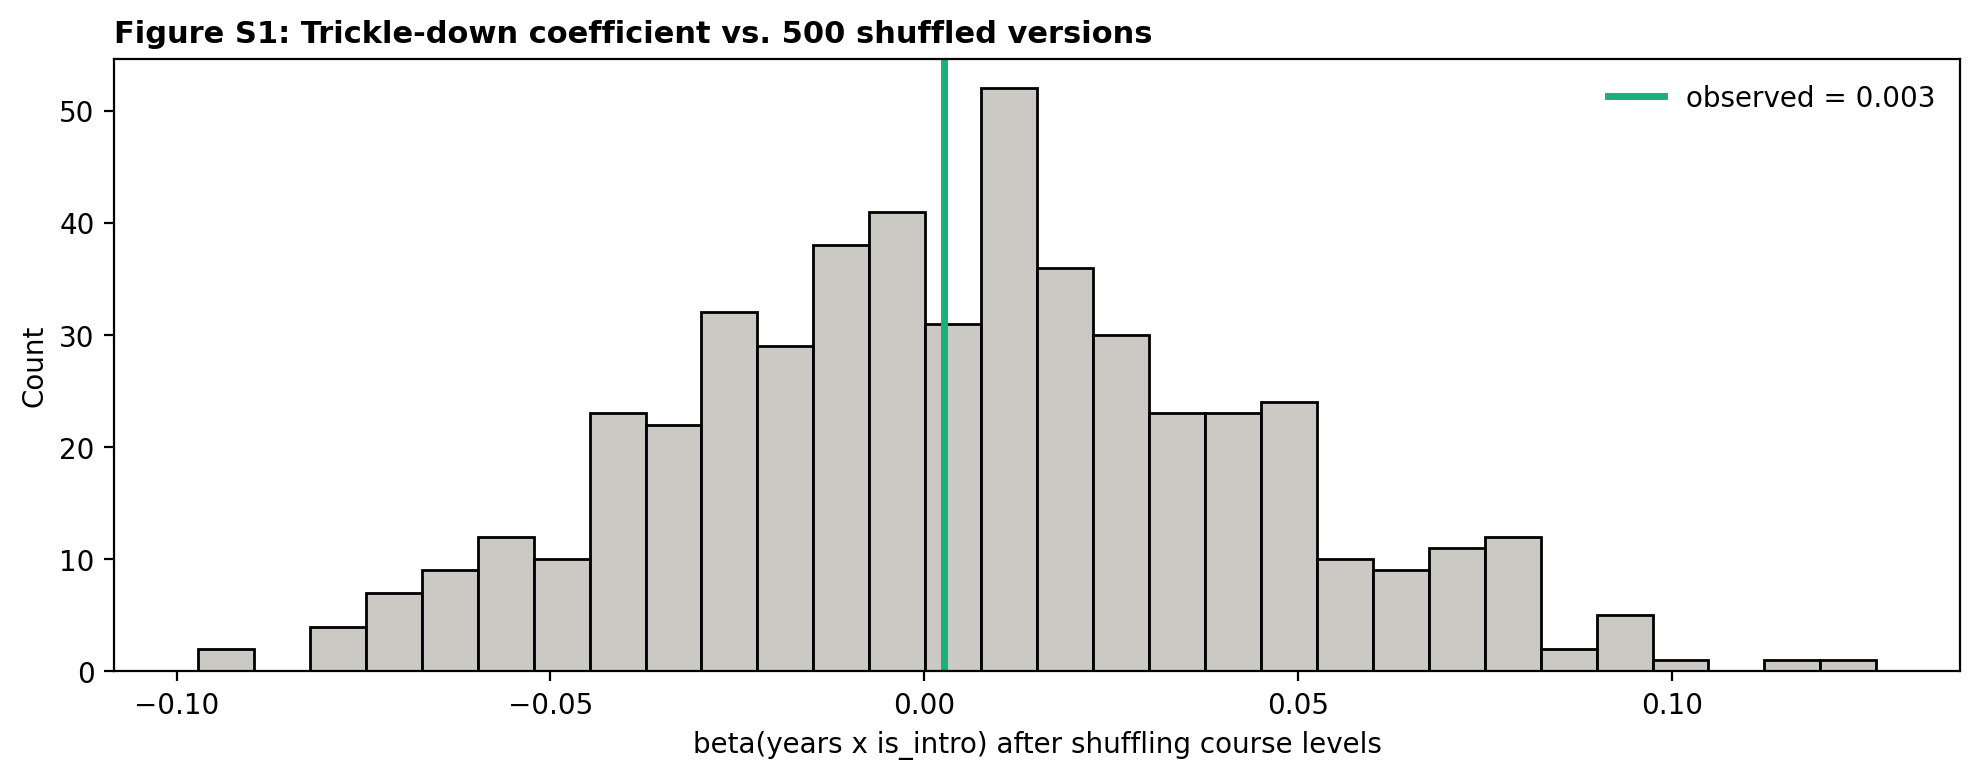

One-sided p-value (share of shuffled betas >= observed): 0.520
Two-sided p-value (share of |shuffled betas| >= |observed|): 0.948


In [30]:
# Figure S1: where our real coefficient falls among the shuffled ones
plt.figure(figsize=(10, 4))
seaborn.histplot(perm_coefs, bins=30, color="#b9b8b1")
plt.axvline(observed_a1, color="#1baf7a", linewidth=2.5, label=f"observed = {observed_a1:.3f}")
plt.xlabel("beta(years x is_intro) after shuffling course levels")
plt.title(f"Figure S1: Trickle-down coefficient vs. {n_perm} shuffled versions", loc="left",
          fontsize=11, fontweight="bold")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()
print(f"One-sided p-value (share of shuffled betas >= observed): {np.mean(perm_coefs >= observed_a1):.3f}")
print(f"Two-sided p-value (share of |shuffled betas| >= |observed|): "
      f"{np.mean(np.abs(perm_coefs) >= abs(observed_a1)):.3f}")

Permutation result: Our real coefficient, 0.003, sits in the middle of 500 other shuffled coefficients (Figure S1). The one-sided p-value is 0.52. If course level was not associated with growsth, a coefficient at least this large would appear in about half of all shuffles. So it isn't too large in the end.

Bootstrap: measuring how precise the coefficient is by resampling courses with replacement 500 times, re-fitting each time, and keeping the middle 95% of the estimates.

In [31]:
# Bootstrap 95% confidence interval for the trickle-down coefficient
course_ids = classes["crse_id"].unique()
rows_of_course = classes.groupby("crse_id").indices
n_boot = 500
boot_coefs = np.zeros(n_boot)
for i in range(n_boot):
    sampled_courses = np.random.choice(course_ids, len(course_ids), replace=True)
    sample = classes.iloc[np.concatenate([rows_of_course[c] for c in sampled_courses])]
    model = sm.Logit(sample["is_ai"], sm.add_constant(sample[A1_INPUTS])).fit(disp=0)
    boot_coefs[i] = model.params["years_x_intro"]
low, high = np.percentile(boot_coefs, [2.5, 97.5])
print(f"95% bootstrap confidence interval for beta(years x is_intro): [{low:.3f}, {high:.3f}]")
print(f"As odds ratios: [{np.exp(low):.2f}, {np.exp(high):.2f}]  (1 = intro and grad odds grow at the same speed)")

95% bootstrap confidence interval for beta(years x is_intro): [-0.091, 0.220]
As odds ratios: [0.91, 1.25]  (1 = intro and grad odds grow at the same speed)


What Analysis 1's tests mean together:
- Result: The 95% bootstrap interval for the trickle-down odds ratio is 0.91 to 1.25. The regression (p = 0.967), the permutation test (p = 0.52), and the bootstrap agree and do not conflict each other, so we fail to reject the null hypothesis that intro and graduate courses grow at the same speed.
- This matters becuase equal growth still puts intro students behind in AI adaptation for their course levels. Both levels grow about 16% a year, but they start from very different starting sizes, so the gaps between the two keep increasing rather than staying the same. In Fall 2026, a graduate class was about six times as likely as an intro class to be AI/ML (4.73% vs. 0.74% according to Table E2). A student who wants AI/ML before specializing still has fewer options.
- Limits: Failing to reject is not proof of absolutely no effect. With only 19 intro AI courses, a moderate real difference could hide inside that wide interval, and the hand-checked flag points toward faster intro growth (Section 5), although that check is not completely stable. Also, the administration could be planning to incorporate vastly more intro-level courses for next semester or even the next few semesters, which we would have no way of knowing.

#### Analysis 2: could the non-computing trend be chance?
We shuffle which semester each listing belongs to within its own department. Each department keeps its size and number of AI listings, and the timing is changed. If AI listings were not becoming more common over time, the real β should look like the shuffled values.

In [32]:
# Permutation test for Analysis 2
# Null hypothesis: within a department, AI listings are no more likely in later semesters.
semester_years = listings.groupby("term_index")["years_since_start"].first()
semester_trends = listings.groupby("term_index")["trends_lag1"].first()
observed_a2 = a2.params["years_since_start"]
n_perm2 = 300
perm_coefs2 = np.zeros(n_perm2)
shuffled_data2 = listings.copy()
for i in range(n_perm2):
    shuffled_term = shuffled_data2.groupby("department")["term_index"].transform(
        lambda s: np.random.permutation(s.values))
    shuffled_data2["years_since_start"] = shuffled_term.map(semester_years)
    shuffled_data2["trends_lag1"] = shuffled_term.map(semester_trends)
    shuffled_data2["years_x_computing"] = shuffled_data2["years_since_start"] * shuffled_data2["is_computing"]
    model = sm.Logit(shuffled_data2["is_ai"], sm.add_constant(shuffled_data2[A2_INPUTS])).fit(disp=0)
    perm_coefs2[i] = model.params["years_since_start"]

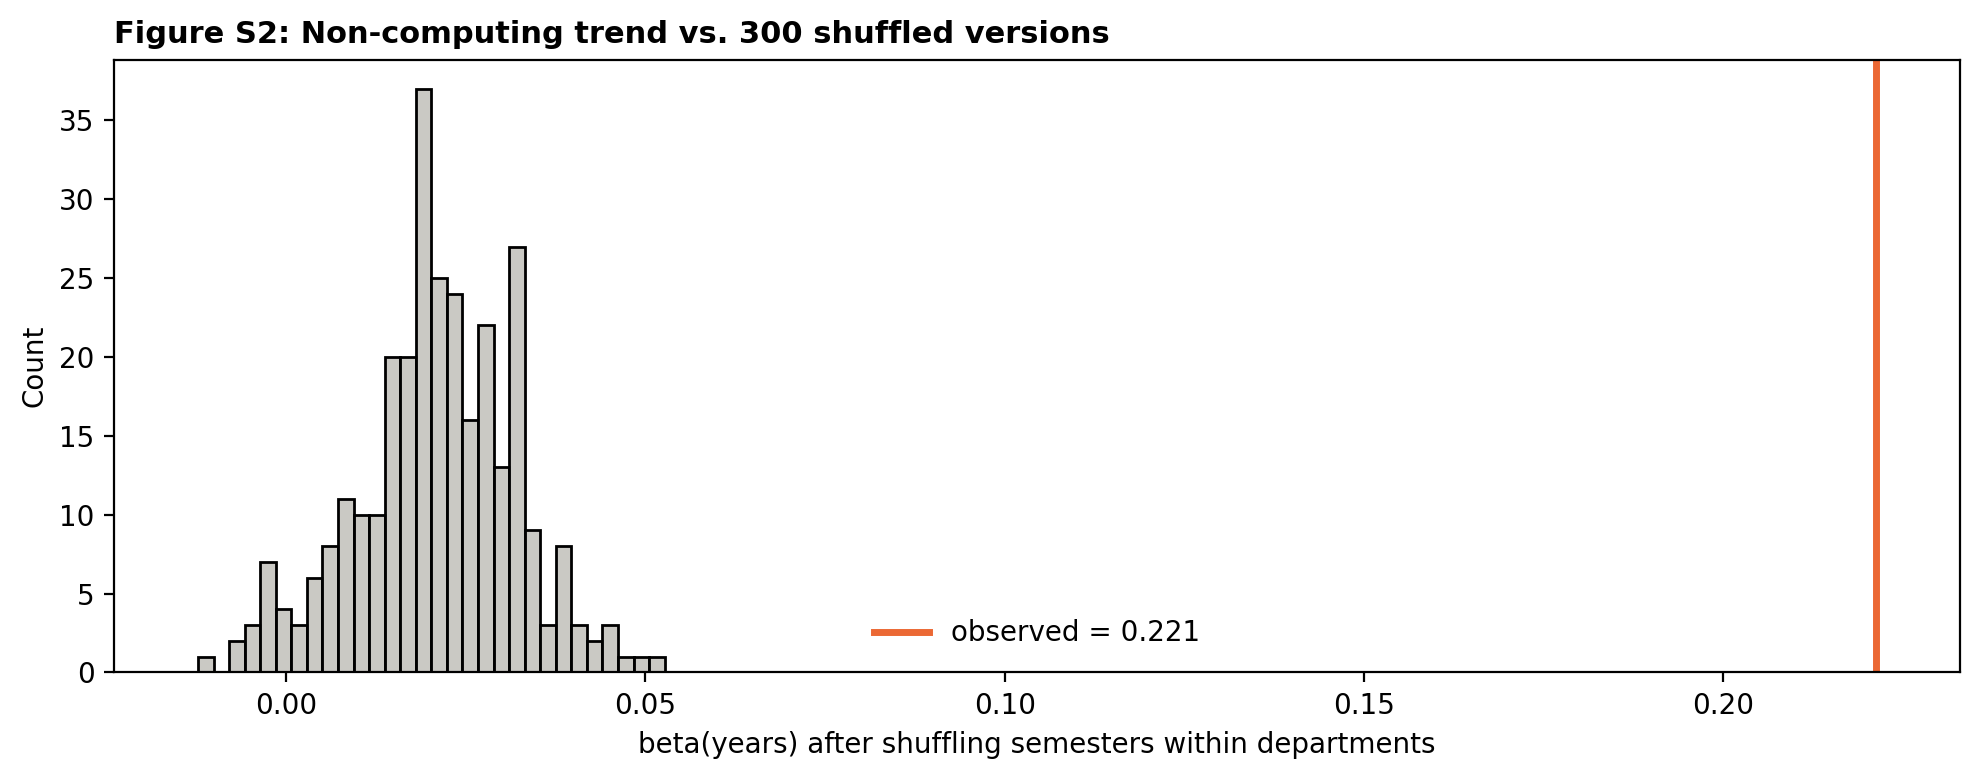

Observed beta(years) = 0.221; largest of 300 shuffled betas = 0.053
One-sided p-value (share of shuffled betas >= observed): 0.000 (none of the 300 shuffles reached it, so p < 0.0033)


In [33]:
# Figure S2: the real non-computing trend vs. the shuffled ones
plt.figure(figsize=(10, 4))
seaborn.histplot(perm_coefs2, bins=30, color="#b9b8b1")
plt.axvline(observed_a2, color="#eb6834", linewidth=2.5, label=f"observed = {observed_a2:.3f}")
plt.xlabel("beta(years) after shuffling semesters within departments")
plt.title(f"Figure S2: Non-computing trend vs. {n_perm2} shuffled versions", loc="left",
          fontsize=11, fontweight="bold")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()
print(f"Observed beta(years) = {observed_a2:.3f}; largest of {n_perm2} shuffled betas = {perm_coefs2.max():.3f}")
print(f"One-sided p-value (share of shuffled betas >= observed): {np.mean(perm_coefs2 >= observed_a2):.3f} "
      f"(none of the {n_perm2} shuffles reached it, so p < {1 / n_perm2:.4f})")

What Analysis 2's test means:
- The real β(years) is 0.221, and the largest of 300 shuffled values is 0.053 (around 1/4 times as large), and no shuffle reached ours (Figure S2), so p < 1/300 ≈ 0.003. Together with the regression and every robustness check, we reject the null hypothesis that non-computing listings are not becoming more likely to be AI/ML over time.
- Why it matters: The growth in AI outside computing is a trend across many departments, which is letting students find AI in departments outside strict CS-related fields.

## Conclusions
We explored how AI/ML spread across course levels and disciplines at Cornell from Fall 2014 to Fall 2026, and whether the spread tracked public interest.

| Question | Answer | Key evidence | Confidence |
|---|---|---|---|
| 1. Trickle-down across levels? | No evidence | Interaction odds ratio 1.003, p = 0.97 (Sec. 2) | Moderate: only 19 intro AI courses |
| 2. Spreading beyond computing? | Yes | Non-computing +24.8%/yr vs. computing +6.0%/yr (Sec. 3) | High |
| 3. Following public interest? | Same direction, not semester to semester | Trends odds ratio 0.991 per +10 pts, p = 0.49 (Table T1) | Moderate: Trends is a rough measure |
| 4. Taught or discussed outside computing? | Mostly discussed | Social sci., business & law: 59% discuss vs. 18% teach (Table L2) | Low: 49 labeled courses |

1. Trickle-down across course levels: AI/ML grew at every level, and graduate courses led at both the start and end of our data. With our preregistered keyword flag, intro and graduate odds both grew around 16% yearly, and all three significance methods agree that any differences are indistinguishable from chance. Since intro course adaptation starts a lot lower, equal growth still leads to a widening gap between the two. In Fall 2026, 4.73% of graduate classes were AI/ML, compared to 0.74% of intro classes. Our hand labels showed that most early intro "AI" courses only mentioned AI. When we removed those, intro odds grew faster. Since we labeled every intro course but only a sample of graduate courses, we treat this as an exploration instead of an actual finding.

2. Across disciplines: non-computing odds grew 24.8% a year compared with 6.0% in computing, no permutation came close to the real trend, and it held in our robustness checks. Non-computing departments with an AI/ML course went from 5 to 39, and 69% of distinct AI/ML courses are outside computing.

3. Public interest: the catalog and Google search interest rise together, but Trends adds nothing once steady growth is in the model (Table T1). Cornell's catalog seems to change slowly due to the beauracracy involved with designing and implementing coursees, so short bursts of public attention don't immediately reflect in the next semester.

4. Taught or discussed: in the courses we checked, AI in computing and engineering is mostly taught, while AI in the social sciences is mostly discussed. Our small sample suggests AI is entering non-technical fields more as a topic than as a quantitative subject / method.

Implications: Students outside computing are increasingly likely to at least find AI in their own major somehow, but mostly as a subject of a discussion. Students early in their course journey still have fewer AI/ML options than graduate students.

## Limitations

1. Keyword matching limitations
   - False positives: Networks (ECON 2040 and its cross-listings) is flagged because "neural networks" appears in a topic list, and courses like CS 4820 (algorithms) and PLBIO 2490 (Hollywood Biology) mention AI without teaching it.
   - False negatives: special-topics seminars that use ML but don't say so in their descriptions are probably missed.
   - If one misflagged course runs every semester, that single error repeats and can make AI look more widespread than it is.
2. Neither `is_ai` nor `mentions_ai` shows how much class time is spent on AI, which is very hard to measure reliably from catalog data.
3. Undergraduate/graduate twins falsely increase the graduate count. Any instances of twins means that some of the graduate courses comes from graduate versions of undergraduate courses, not separate graduate courses that would actually be a lead.
4. We can't measure how many students actually take these courses. A 500-person lecture has the same weight as a 4-person graduate seminar, which limits what our counts say about student access and involvement in the real world.
5. We do not know what happened before Fall 2014. Courses that were already AI before 2014–15 look like they started then, which can make the first year look like a burst of adoption when it is just the start of our measurement after that adoption already happened.
6. Cross-listing can look like adoption. In Analysis 2, a department gets credit for an AI course it cross-lists even if computing faculty teach it.
7. Discipline groups are partly subjective. Some subjects, such as linguistics, cognitive science, and design, could fit in two groups; we chose the closest fit.
8. Google Trends is a rough measure. It rises over time along with everything else, which makes its separate effect hard to estimate, and it has a sharp 2026 peak (Appendix A).
9. Real-world impact: if administrators read our results at face value, they might conclude that students outside computing already have enough access to AI courses. But our counts can be inflated by false positives, cross-listings and twins, and they ignore enrollment. Acting on them without those caveats could send resources away from the introductory, hands-on AI courses that non-specialists seem to lack.
10. Limits of our significance tests: the intro group has only 19 AI courses, so a non-significant intro result does not mean there is no effect. Our models also assume the log-odds change in a straight line over time, which Figure A1 shows is not true for intro courses.
11. Fall 2026 and the Trends lag: Fall 2026 was still in progress when we collected the data, and a one-semester lag may be too short for course planning, or slow administrative decisions, to react to public interest.
12. Hand labels: we checked every intro course but only a sample of the others, so our corrected flags remove intro false positives more thoroughly than graduate ones. All three of us agreed on only 32% of the intro labels, so the labels themselves may carry some uncertainty.

## Reflection

- From 18 subjects to every subject: our first draft used only 18 hand-picked subjects, which was too small and biased toward finding AI where we expected it. After peer review we scanned every subject, which took a few hours to download but let AI courses show up in places we wouldn't have guessed.
- Cross-listed courses: we ignored cross-listing at first, so one class could be counted up to four times. Now we keep two tables, one that counts each class once and one that counts each department listing (cleaning Step 9).
- Instructor matching: we wanted to match instructors to their publications to see whether AI courses outside computing are taught by AI researchers, but matching names reliably needs ORCID and other checks for every person, so we left it out.

## Source Code

All of our code is on our GitHub: https://github.com/Aidennnnnnnnnn/2950-final-project. This includes `scrape_cornell.py` (data collection), our data cleaning notebook (which outputs every file this notebook loads), and this report.

## Acknowledgments

Data: Cornell University, Office of the University Registrar, Class Roster API (https://classes.cornell.edu/api/2.0/). Google Trends (https://trends.google.com), downloaded with `pytrends` (https://github.com/GeneralMills/pytrends).

Software: pandas, NumPy, Matplotlib, seaborn, statsmodels, DuckDB, requests.

People: Our TA Jingruo Chen, whose Phase II feedback led to our Google Trends spike check, labeling rule, and twin-course check, and whose Phase III and IV feedback shaped this revision. Our peer reviewers, who led us to collect every subject, handle cross-listed courses, and track courses by `crse_id`. Before their feedback we planned to scan only 18 hand-picked subjects, which was both too small and biased toward AI/ML topics.

AI tools: Claude was used to suggest additional analyses beyond what we had in mind, teach us unfamiliar concepts, help write and debug parts of our code, and suggest proofreading. It also helped us rearrange our cells to be a better clarification following phase III feedback.

## References

Börner, K., Scrivner, O., Gallant, M., Ma, S., Liu, X., Chewning, K., Wu, L., & Evans, J. A. (2018). Skill discrepancies between research, education, and jobs reveal the critical need to supply soft skills for the data economy. Proceedings of the National Academy of Sciences, 115(50), 12630–12637. https://doi.org/10.1073/pnas.1804247115

Computing Research Association. (2017). Generation CS: Computer science undergraduate enrollments surge since 2006. https://cra.org/data/Generation-CS/

Cornell University Office of the University Registrar. (n.d.). Class Roster API 2.0. Retrieved October 2026, from https://classes.cornell.edu/api/2.0/

Gebru, T., Morgenstern, J., Vecchione, B., Vaughan, J. W., Wallach, H., Daumé III, H., & Crawford, K. (2021). Datasheets for datasets. Communications of the ACM, 64(12), 86–92. https://doi.org/10.1145/3458723

GeneralMills. (n.d.). pytrends [Computer software]. GitHub. https://github.com/GeneralMills/pytrends

Google. (n.d.-a). FAQ about Google Trends data. Retrieved October 2026, from https://support.google.com/trends/answer/4365533

Google. (n.d.-b). Google Trends. Retrieved October 2026, from https://trends.google.com

Rogers, E. M. (2003). Diffusion of innovations (5th ed.). Free Press.

## Appendix A: The 2026 Google Trends spike (Phase II reviewer question 1)

Our Trends index jumps to 100 in Spring 2026, compared with 47 the semester before. Our models use the previous semester's value, so the spike only enters our models in Fall 2026. Here we check which search term causes it.

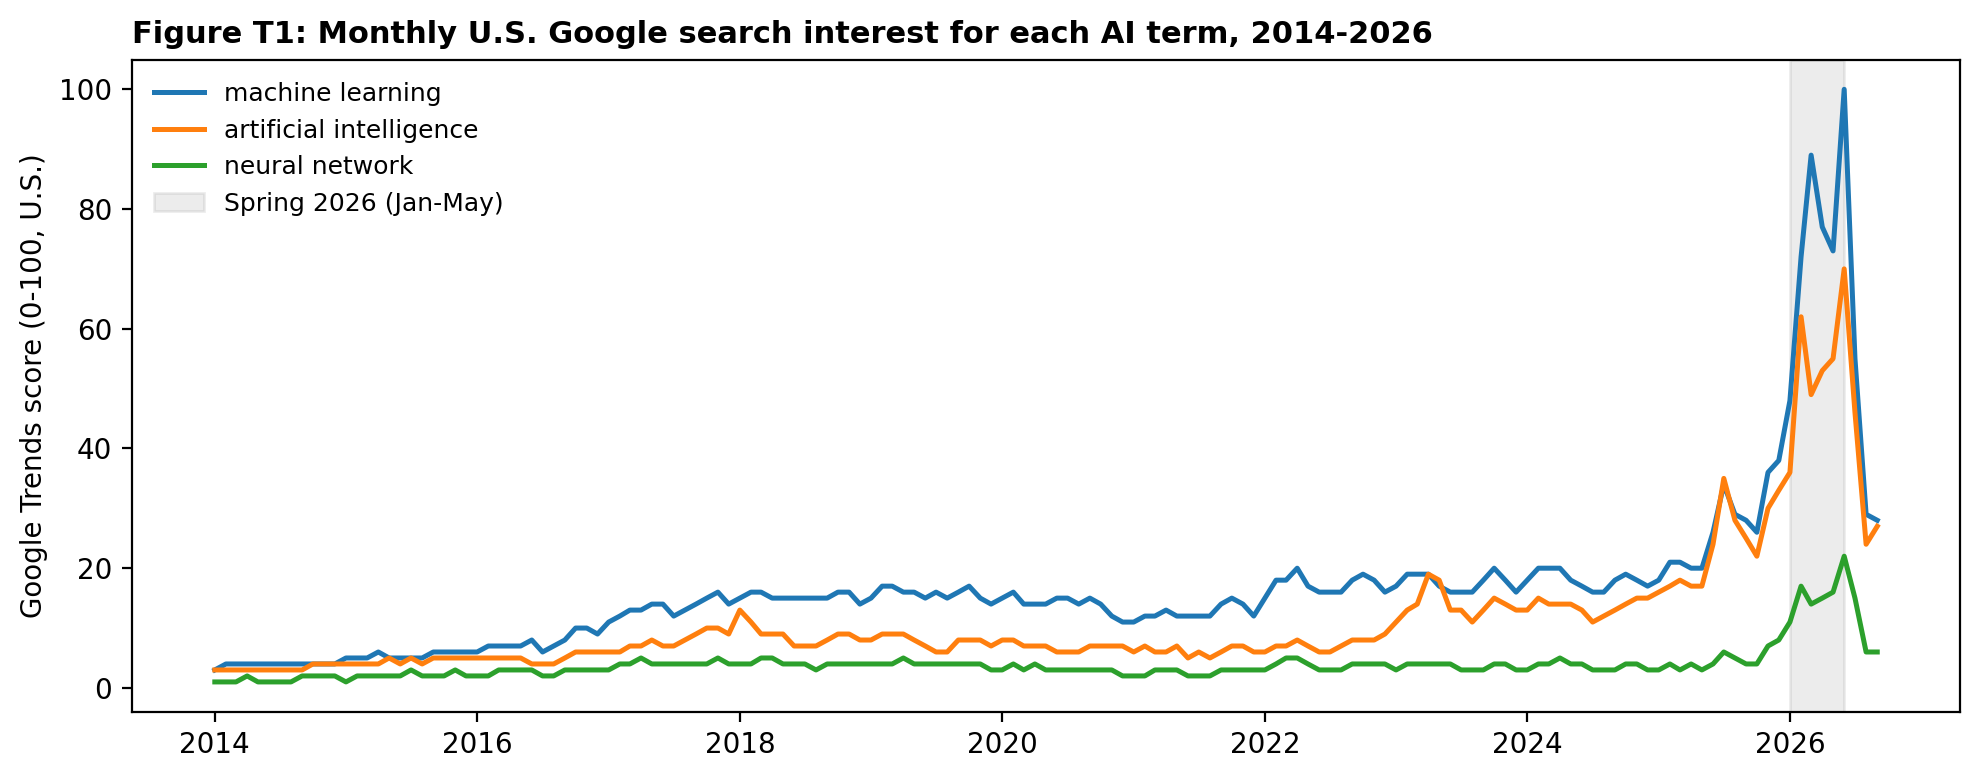

In [34]:
TERMS = ["machine learning", "artificial intelligence", "neural network"]
plt.figure(figsize=(10, 4))
for term in TERMS:
    plt.plot(trends_monthly["date"], trends_monthly[term], linewidth=1.8, label=term)
plt.axvspan(pd.Timestamp("2026-01-01"), pd.Timestamp("2026-05-31"), color="grey", alpha=0.15,
            label="Spring 2026 (Jan-May)")
plt.ylabel("Google Trends score (0-100, U.S.)")
plt.title("Figure T1: Monthly U.S. Google search interest for each AI term, 2014-2026", loc="left",
          fontsize=11, fontweight="bold")
plt.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

In [35]:
# How much each term rose from Fall 2025 to Spring 2026
fall25 = trends_monthly[(trends_monthly["date"] >= "2025-08-01") & (trends_monthly["date"] <= "2025-12-31")][TERMS].mean()
spring26 = trends_monthly[(trends_monthly["date"] >= "2026-01-01") & (trends_monthly["date"] <= "2026-05-31")][TERMS].mean()
change = pd.DataFrame({"Fall 2025 average": fall25, "Spring 2026 average": spring26})
change["increase"] = change["Spring 2026 average"] - change["Fall 2025 average"]
change["share of the total increase"] = change["increase"] / change["increase"].sum()
display(change.round(2))

,Fall 2025 average,Spring 2026 average,increase,share of the total increase
machine learning,31.4,71.8,40.4,0.55
artificial intelligence,27.6,51.0,23.4,0.32
neural network,5.6,14.6,9.0,0.12


All three terms rise from late 2025, peak in June 2026, and fall back to Fall 2025 levels by August 2026. "Machine learning" accounts for about 55% of the increase from Fall 2025 to Spring 2026, "artificial intelligence" 32%, and "neural network" 12%. Since every term jumps at the same time, this is not attributed to a single month's value. It could be a real rise in interest or a change on Google's side. As our reviewer advised, we keep the data and show that removing Fall 2026, the only semester it affects, does not change our findings.